<a href="https://colab.research.google.com/github/cristiancamiloosoriohernandez/Proyecto-Final---Negocios-Verdes-Colombia/blob/main/Proyecto_Final_Negocios_Verdes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROYECTO FINAL ML — NEGOCIOS VERDES DE COLOMBIA
**Objetivo:** encontrar las tendencias de los productos principales y los municipios de origen de los Negocios Verdes registrados, usando reducción de dimensionalidad (PCA, t-SNE) y clustering (K-Means, DBSCAN).

# CARGA DE DATOS

In [ ]:
import requests

# URL de la API de datos.gov.co proporcionada
url = "https://www.datos.gov.co/api/v3/views/v29b-znjj/query.json"

# Realizar la petición GET
respuesta = requests.get(url)

if respuesta.status_code == 200:
    # Convertir la respuesta a formato JSON
    datos = respuesta.json()
    print("¡Consulta exitosa a datos.gov.co!")
    # Mostramos los primeros 5 elementos para no saturar la pantalla si son muchos datos
    display(datos[:5] if isinstance(datos, list) else datos)
else:
    print(f"Error al consultar la API. Código de estado: {respuesta.status_code}")
    print(respuesta.text)

¡Consulta exitosa a datos.gov.co!


[{':id': 'row-vnx2_74x9_crap',
  ':version': 'rv-e4vz_gxxx.rbv8',
  ':created_at': '2023-06-22T15:34:57.330Z',
  ':updated_at': '2023-06-22T15:34:57.330Z',
  'a_o_a_o_de_registro': '2022',
  'autoridad_ambiental_donde': 'CORPOCESAR',
  'regi_n_donde_se_encuentra': 'No registra',
  'departamento_donde_se': 'Cesar',
  'municipio_donde_se_encuentra': 'Valledupar',
  'raz_n_social_del_negocio': 'Hoteles De Upar SAS',
  'descripci_n_del_negocio_verde': 'Hoteles de Upar SAS, presta el servicio de hospedaje a todas las personas interesadas en pasar una o varias noches en el hotel. Los clientes hacen la reserva y el sistema bloquea las habitaciones. Una vez ingresado al hotel el huésped queda libre y puede acceder y disfrutar de todos los servicios que se ofrecen en este magnífico hospedaje. Este hotel se caracteriza por brindarle al cliente comodidad y el mejor trato, propenden por mostrarle a cada persona el aspecto cultural de la ciudad y las buenas costumbres de su población. El hotel hace

In [ ]:
import pandas as pd

dataset = pd.DataFrame(datos)
dataset.head()

,:id,:version,:created_at,:updated_at,a_o_a_o_de_registro,autoridad_ambiental_donde,regi_n_donde_se_encuentra,departamento_donde_se,municipio_donde_se_encuentra,raz_n_social_del_negocio,descripci_n_del_negocio_verde,categor_a_del_negocio_verde,sector_al_cual_pertenece,subsector_al_cual_pertenece,producto_principal_que,categor_a_comercial_al_cual,nombre_representante_del
0,row-vnx2_74x9_crap,rv-e4vz_gxxx.rbv8,2023-06-22T15:34:57.330Z,2023-06-22T15:34:57.330Z,2022,CORPOCESAR,No registra,Cesar,Valledupar,Hoteles De Upar SAS,"Hoteles de Upar SAS, presta el servicio de hos...",2. Ecoproductos Industriales,2.3. Construcción sostenible,2.3.1. Construcción sostenible,Alojamiento,No registra,María Fernanda Villabona Hernández
1,row-5gtv-2dju-45qv,rv-v5kf-wepm-7b8a,2023-06-22T15:34:57.330Z,2023-06-22T15:34:57.330Z,2022,CORPOCESAR,No registra,Cesar,Agustín Codazzi,La Mellita,La empresa la Mellita produce (queso de cabra ...,1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.1. Agroindustrial alimentario,Queso de cabra,No registra,Claudia Patricia Gomez Alvarez
2,row-e6be~67w3-kf4n,rv-266q.vqhi-m9y7,2023-06-22T15:34:57.330Z,2023-06-22T15:34:57.330Z,2022,CORPOCESAR,No registra,Cesar,La Jagua de Ibirico,Vinos Kike,El proceso de Vinos Kike comienza con la compr...,1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.1. Agroindustrial alimentario,Vino Artesanal de Corozo,No registra,Edgar Enrrique Daza Reyes
3,row-qr44-4nng-67z5,rv-5su2_27we_kh2u,2023-06-22T15:34:57.330Z,2023-06-22T15:34:57.330Z,2022,CORPOCESAR,No registra,Cesar,Valledupar,Delitcha,"Delitcha, es una empresa que se encarga de rea...",1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.1. Agroindustrial alimentario,Encurtidos y Aderezos,No registra,Graciela Alix Ramos Fernández
4,row-wwwy_kxu8~2x83,rv-ae4u.58i3_3y5f,2023-06-22T15:34:57.330Z,2023-06-22T15:34:57.330Z,2022,CORPOCESAR,No registra,Cesar,Valledupar,Fundación Mentes Brillantes Para El Mundo,Fundación Mentes Brillantes Para el Mundo es u...,2. Ecoproductos Industriales,2.1. Aprovechamiento y valoración de Residuos,2.1.2. Aprovechamiento de residuos inorgánicos,"Plan envases y empaques (recolección, separaci...",No registra,Niriam Avendaño Agudelo


# INSPECCIÓN

### Preparación del entorno de trabajo

In [ ]:
# Importar librerias
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from unidecode import unidecode
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
import scipy.sparse as sp

In [ ]:
# Crear copia del original para trabajar
tabla = dataset.copy()

### Limpieza y transformación de datos

In [ ]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   :id                            4199 non-null   object
 1   :version                       4199 non-null   object
 2   :created_at                    4199 non-null   object
 3   :updated_at                    4199 non-null   object
 4   a_o_a_o_de_registro            4199 non-null   object
 5   autoridad_ambiental_donde      4199 non-null   object
 6   regi_n_donde_se_encuentra      4199 non-null   object
 7   departamento_donde_se          4199 non-null   object
 8   municipio_donde_se_encuentra   4199 non-null   object
 9   raz_n_social_del_negocio       4199 non-null   object
 10  descripci_n_del_negocio_verde  4199 non-null   object
 11  categor_a_del_negocio_verde    4199 non-null   object
 12  sector_al_cual_pertenece       4199 non-null   object
 13  sub

In [ ]:
# Conteo de duplicados

tabla.duplicated().sum()

np.int64(0)

In [ ]:
# Normalizar encabezados
tabla.columns

Index([':id', ':version', ':created_at', ':updated_at', 'a_o_a_o_de_registro',
       'autoridad_ambiental_donde', 'regi_n_donde_se_encuentra',
       'departamento_donde_se', 'municipio_donde_se_encuentra',
       'raz_n_social_del_negocio', 'descripci_n_del_negocio_verde',
       'categor_a_del_negocio_verde', 'sector_al_cual_pertenece',
       'subsector_al_cual_pertenece', 'producto_principal_que',
       'categor_a_comercial_al_cual', 'nombre_representante_del'],
      dtype='object')

In [ ]:
# Depurar datos

tabla.drop(columns=[':id', ':version', ':created_at', ':updated_at', 'descripci_n_del_negocio_verde', 'nombre_representante_del'], inplace=True)
tabla.columns

Index(['a_o_a_o_de_registro', 'autoridad_ambiental_donde',
       'regi_n_donde_se_encuentra', 'departamento_donde_se',
       'municipio_donde_se_encuentra', 'raz_n_social_del_negocio',
       'categor_a_del_negocio_verde', 'sector_al_cual_pertenece',
       'subsector_al_cual_pertenece', 'producto_principal_que',
       'categor_a_comercial_al_cual'],
      dtype='object')

In [ ]:
# Normalización de nombres de columnas según pagina de origen

tabla.rename(columns = {'a_o_a_o_de_registro':"ANO REGISTRO",
              'autoridad_ambiental_donde':"AUTORIDAD AMBIENTAL",
              'regi_n_donde_se_encuentra':"REGION",
              'departamento_donde_se':"DEPARTAMENTO",
              'municipio_donde_se_encuentra':"MUNICIPIO",
              'raz_n_social_del_negocio':"RAZON SOCIAL",
              'categor_a_del_negocio_verde':"CATEGORIA",
              'sector_al_cual_pertenece':"SECTOR",
              'subsector_al_cual_pertenece':"SUBSECTOR",
              'producto_principal_que':"PRODUCTO PRINCIPAL",
              'categor_a_comercial_al_cual':"CATEGORIA COMERCIAL"}, inplace=True)
tabla.columns

Index(['ANO REGISTRO', 'AUTORIDAD AMBIENTAL', 'REGION', 'DEPARTAMENTO',
       'MUNICIPIO', 'RAZON SOCIAL', 'CATEGORIA', 'SECTOR', 'SUBSECTOR',
       'PRODUCTO PRINCIPAL', 'CATEGORIA COMERCIAL'],
      dtype='object')

In [ ]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ANO REGISTRO         4199 non-null   object
 1   AUTORIDAD AMBIENTAL  4199 non-null   object
 2   REGION               4199 non-null   object
 3   DEPARTAMENTO         4199 non-null   object
 4   MUNICIPIO            4199 non-null   object
 5   RAZON SOCIAL         4199 non-null   object
 6   CATEGORIA            4199 non-null   object
 7   SECTOR               4199 non-null   object
 8   SUBSECTOR            4199 non-null   object
 9   PRODUCTO PRINCIPAL   4199 non-null   object
 10  CATEGORIA COMERCIAL  4187 non-null   object
dtypes: object(11)
memory usage: 361.0+ KB


In [ ]:
### Normalización de datos preestablecidos ###

tabla["ANO REGISTRO"] = tabla["ANO REGISTRO"].str.strip()
sorted(tabla["ANO REGISTRO"].unique())

['2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022']

In [ ]:
tabla["AUTORIDAD AMBIENTAL"] = tabla["AUTORIDAD AMBIENTAL"].str.strip()
tabla['AUTORIDAD AMBIENTAL'].unique()

array(['CORPOCESAR', 'CAR', 'CAM', 'CORPORINOQUÍA', 'CORPOAMAZONÍA',
       'CODECHOCÓ', 'CSB', 'CARSUCRE', 'CRC', 'CAS', 'CVC', 'CARDIQUE',
       'CDA', 'CDMB', 'CORALINA', 'CORPOMOJANA', 'CORMACARENA',
       'CORPONARIÑO', 'CORPAMAG', 'CORPOBOYACÁ', 'EPA Buenaventura',
       'CORPONOR', 'EPA Cartagena', 'CORPOGUAJIRA', 'CORANTIOQUIA',
       'CORTOLIMA', 'CORPOURABÁ', 'CRA', 'EPA Barranquilla Verde', 'CVS',
       'DADSA', 'CORPOCALDAS', 'SDA', 'CRQ', 'EPA CARTAGENA', 'CARDER',
       'EPA BUENAVENTURA', 'AMVA', 'CORPOGUAVIO', 'CORPOCHIVOR',
       'CORNARE', 'Corpoboyacá', 'EPA BARRANQUILLA VERDE', 'Corponor',
       'Crq', 'DAGMA', 'Cormacarena'], dtype=object)

In [ ]:
reemplazos_autoridad_ambiental = {'Cormacarena':'CORMACARENA',
                                  'Corpoboyacá':'CORPOBOYACÁ',
                                  'Corponor': 'CORPONOR',
                                  'Crq': 'CRQ',
                                  'EPA Barranquilla Verde' : 'EPA BARRANQUILLA VERDE',
                                  'EPA Buenaventura' : 'EPA BUENAVENTURA',
                                  'EPA Cartagena' : 'EPA CARTAGENA'}

tabla['AUTORIDAD AMBIENTAL'] = tabla['AUTORIDAD AMBIENTAL'].replace(reemplazos_autoridad_ambiental)
tabla['AUTORIDAD AMBIENTAL'].unique()

array(['CORPOCESAR', 'CAR', 'CAM', 'CORPORINOQUÍA', 'CORPOAMAZONÍA',
       'CODECHOCÓ', 'CSB', 'CARSUCRE', 'CRC', 'CAS', 'CVC', 'CARDIQUE',
       'CDA', 'CDMB', 'CORALINA', 'CORPOMOJANA', 'CORMACARENA',
       'CORPONARIÑO', 'CORPAMAG', 'CORPOBOYACÁ', 'EPA BUENAVENTURA',
       'CORPONOR', 'EPA CARTAGENA', 'CORPOGUAJIRA', 'CORANTIOQUIA',
       'CORTOLIMA', 'CORPOURABÁ', 'CRA', 'EPA BARRANQUILLA VERDE', 'CVS',
       'DADSA', 'CORPOCALDAS', 'SDA', 'CRQ', 'CARDER', 'AMVA',
       'CORPOGUAVIO', 'CORPOCHIVOR', 'CORNARE', 'DAGMA'], dtype=object)

In [ ]:
tabla["REGION"] = tabla["REGION"].str.strip()
tabla['REGION'].unique()

array(['No registra', 'Central', 'Caribe', 'Pacífico', 'Santanderes',
       'eje cafetero y Antioquia', 'Llano', 'Seaflower',
       'Eje cafetero y Antioquia', 'Amazonía', 'Eje Cafetero y Antioquia'],
      dtype=object)

In [ ]:
reemplazos_region = {'eje cafetero y Antioquia' : 'Eje Cafetero y Antioquia',
                     'Eje cafetero y Antioquia' : 'Eje Cafetero y Antioquia'}

tabla['REGION'] = tabla['REGION'].replace(reemplazos_region)
tabla['REGION'].unique()

array(['No registra', 'Central', 'Caribe', 'Pacífico', 'Santanderes',
       'Eje Cafetero y Antioquia', 'Llano', 'Seaflower', 'Amazonía'],
      dtype=object)

In [ ]:
tabla["DEPARTAMENTO"] = tabla["DEPARTAMENTO"].str.strip()
sorted(tabla['DEPARTAMENTO'].unique())

['Amazonas',
 'Antioquia',
 'Arauca',
 'Archipiélago de San Andrés, Providencia y Santa Catalina',
 'Atlántico',
 'BOYACÁ',
 'Bogotá, D.C.',
 'Bolívar',
 'Boyacá',
 'Caldas',
 'Caquetá',
 'Casanare',
 'Cauca',
 'Cesar',
 'Chocó',
 'Cundinamarca',
 'Córdoba',
 'Guainía',
 'Guaviare',
 'Huila',
 'La Guajira',
 'Magdalena',
 'Meta',
 'Nariño',
 'Norte de Santander',
 'Putumayo',
 'Quindío',
 'Risaralda',
 'San Andrés',
 'Santander',
 'Sucre',
 'Tolima',
 'Valle del Cauca',
 'Vaupés',
 'Vichada']

In [ ]:
tabla["MUNICIPIO"] = tabla["MUNICIPIO"].str.strip()
tabla['MUNICIPIO'].unique()

array(['Valledupar', 'Agustín Codazzi', 'La Jagua de Ibirico',
       'Aguachica', 'La Calera', 'Río de Oro', 'San Martín - Ces',
       'Campoalegre', 'Garzón', 'Fortul', 'Florencia - Caq', 'Hobo',
       'Neiva', 'Paicol', 'Palermo', 'Nuquí', 'Teruel', 'Timaná',
       'Iquira', 'Pitalito', 'Santa Rosa del Sur', 'Palmito', 'Ovejas',
       'Chalán', 'Tolú Viejo', 'Santander de Quilichao', 'Coloso',
       'Concepción - San', 'Buenaventura rural', 'Albania - Sant',
       'Mogotes', 'San Vicente de Chucurí', 'Málaga', 'Carcasí',
       'Cartagena de indias', 'San Gil', 'El Carmen de Chucurí',
       'Inírida', 'Popayán', 'San José del Guaviare', 'Mitú', 'Puracé',
       'Girón', 'Piedecuesta', 'Lebríja', 'Bucaramanga',
       'San Andrés - Isl', 'El Paujil', 'Zambrano', 'Providencia - Isl',
       'Sucre - Suc', 'Puerto Gaitán', 'Mesetas', 'Uribe',
       'San Martín - Met', 'Villavicencio', 'Lejanías', 'Restrepo - Met',
       'Fuente de oro', 'Samaniego', 'Puerto Asís', 'Ciénaga', '

In [ ]:
reemplazos_MNCP = {
    "ANSERMANUEVO": "Ansermanuevo",
    "ARBOLEDAS": "Arboledas",
    "Abejorral": "Abejorral",
    "Abriaquí": "Abriaquí",
    "Acacías": "Acacías",
    "Acandí": "Acandí",
    "Acevedo": "Acevedo",
    "Achí": "Achí",
    "Aguachica": "Aguachica",
    "Aguada": "Aguada",
    "Aguadas": "Aguadas",
    "Aguazul": "Aguazul",
    "Agustín Codazzi": "Agustín Codazzi",
    "Agustín codazzi": "Agustín Codazzi",
    "Aipe": "Aipe",
    "Albania": "Albania",
    "Albania - Sant": "Albania",
    "Albán": "Albán",
    "Alcalá": "Alcalá",
    "Aldana": "Aldana",
    "Alejandría": "Alejandría",
    "Algeciras": "Algeciras",
    "Alpujarra": "Alpujarra",
    "Alto Baudó": "Alto Baudó",
    "Altos del Rosario": "Altos del Rosario",
    "Alvarado": "Alvarado",
    "Amalfi": "Amalfi",
    "Anapoima": "Anapoima",
    "Ancuya": "Ancuya",
    "Andalucía": "Andalucía",
    "Angostura": "Angostura",
    "Anolaima": "Anolaima",
    "Anorí": "Anorí",
    "Anserma": "Anserma",
    "Ansermanuevo": "Ansermanuevo",
    "Anzoátegui": "Anzoátegui",
    "Apartadó": "Apartadó",
    "Apulo": "Apulo",
    "Apía": "Apía",
    "Aquitania": "Aquitania",
    "Aracataca": "Aracataca",
    "Aranzazu": "Aranzazu",
    "Aratoca": "Aratoca",
    "Arauquita": "Arauquita",
    "Arbeláez": "Arbeláez",
    "Arboledas": "Arboledas",
    "Arboletes": "Arboletes",
    "Arcabuco": "Arcabuco",
    "Arenal": "Arenal",
    "Argelia": "Argelia",
    "Arjona": "Arjona",
    "Armenia": "Armenia",
    "Astrea": "Astrea",
    "Ataco": "Ataco",
    "Atrato": "Atrato",
    "Ayapel": "Ayapel",
    "BARBACOAS": "Barbacoas",
    "Bahía Solano": "Bahía Solano",
    "Bahía solano": "Bahía Solano",
    "Bajo Baudó": "Bajo Baudó",
    "Balboa": "Balboa",
    "Baranoa": "Baranoa",
    "Baraya": "Baraya",
    "Barbacoas": "Barbacoas",
    "Barbosa": "Barbosa",
    "Barichara": "Barichara",
    "Barrancabermeja": "Barrancabermeja",
    "Barrancas": "Barrancas",
    "Barranco de Loba": "Barranco de Loba",
    "Barranquilla": "Barranquilla",
    "Barranquilla rural": "Barranquilla rural",
    "Barranquilla urbana": "Barranquilla urbana",
    "Belalcázar": "Belalcázar",
    "Bello": "Bello",
    "Bello rural": "Bello rural",
    "Belmira": "Belmira",
    "Belén": "Belén",
    "Belén de Los Andaquies": "Belén de los Andaquíes",
    "Belén de Los Andaquíes": "Belén de los Andaquíes",
    "Belén de Umbría": "Belén de Umbría",
    "Bituima": "Bituima",
    "Bochalema": "Bochalema",
    "Bogotá, D.C.": "Bogotá, D.C.",
    "Bojacá": "Bojacá",
    "Bojayá": "Bojayá",
    "Bolívar": "Bolívar",
    "Boyacá": "Boyacá",
    "Briceño - Ant": "Briceño",
    "Bucaramanga": "Bucaramanga",
    "Buenaventura": "Buenaventura",
    "Buenaventura rural": "Buenaventura rural",
    "Buenaventura urbana": "Buenaventura urbana",
    "Buenavista": "Buenavista",
    "Buesaco": "Buesaco",
    "Bugalagrande": "Bugalagrande",
    "Cabuyaro": "Cabuyaro",
    "Cachipay": "Cachipay",
    "Caicedonia": "Caicedonia",
    "Caimito": "Caimito",
    "Cajamarca": "Cajamarca",
    "Cajibío": "Cajibío",
    "Cajicá": "Cajicá",
    "Calamar": "Calamar",
    "Calarcá": "Calarcá",
    "Caldas": "Caldas",
    "Cali": "Cali",
    "Cali rural": "Cali rural",
    "California": "California",
    "Calima": "Calima",
    "Campoalegre": "Campoalegre",
    "Campohermoso": "Campohermoso",
    "Candelaria": "Candelaria",
    "Cantagallo": "Cantagallo",
    "Caparrapí": "Caparrapí",
    "Capitanejo": "Capitanejo",
    "Caracolí": "Caracolí",
    "Caramanta": "Caramanta",
    "Carcasí": "Carcasí",
    "Carepa": "Carepa",
    "Carmen de Carupa": "Carmen de Carupa",
    "Cartagena Urbana": "Cartagena urbana",
    "Cartagena de Indias": "Cartagena de Indias",
    "Cartagena de indias": "Cartagena de Indias",
    "Cartagena del Chairá": "Cartagena del Chairá",
    "Cartagena rural": "Cartagena rural",
    "Cartagena urbana": "Cartagena urbana",
    "Cartago": "Cartago",
    "Caucasia": "Caucasia",
    "Cañasgordas": "Cañasgordas",
    "Cereté": "Cereté",
    "Cerrito": "Cerrito",
    "Cerro de San Antonio": "Cerro de San Antonio",
    "Chachagüí": "Chachagüí",
    "Chaguaní": "Chaguaní",
    "Chalán": "Chalán",
    "Chaparral": "Chaparral",
    "Charalá": "Charalá",
    "Charta": "Charta",
    "Chigorodó": "Chigorodó",
    "Chimichagua": "Chimichagua",
    "Chinavita": "Chinavita",
    "Chinchiná": "Chinchiná",
    "Chinácota": "Chinácota",
    "Chinú": "Chinú",
    "Chipaque": "Chipaque",
    "Chiquinquirá": "Chiquinquirá",
    "Chiriguaná": "Chiriguaná",
    "Chitagá": "Chitagá",
    "Chitaraque": "Chitaraque",
    "Chivor": "Chivor",
    "Chocontá": "Chocontá",
    "Chía": "Chía",
    "Cicuco": "Cicuco",
    "Circasia": "Circasia",
    "Ciénaga": "Ciénaga",
    "Ciénaga de Oro": "Ciénaga de Oro",
    "Ciénega": "Ciénega",
    "Cocorná": "Cocorná",
    "Cogua": "Cogua",
    "Colombia": "Colombia",
    "Coloso": "Colosó",
    "Colosó": "Colosó",
    "Colón": "Colón",
    "Concepción": "Concepción",
    "Concepción - San": "Concepción",
    "Concordia": "Concordia",
    "Confines": "Confines",
    "Consaca": "Consacá",
    "Consacá": "Consacá",
    "Contratación": "Contratación",
    "Convención": "Convención",
    "Coper": "Coper",
    "Corozal": "Corozal",
    "Cota": "Cota",
    "Cotorra": "Cotorra",
    "Coveñas": "Coveñas",
    "Coyaima": "Coyaima",
    "Cravo Norte": "Cravo Norte",
    "Cubarral": "Cubarral",
    "Cucunubá": "Cucunubá",
    "Cumaral": "Cumaral",
    "Cumaribo": "Cumaribo",
    "Cumbal": "Cumbal",
    "Curillo": "Curillo",
    "Curití": "Curití",
    "Curumaní": "Curumaní",
    "Cuítiva": "Cuítiva",
    "Cáceres": "Cáceres",
    "Cáchira": "Cáchira",
    "Cácota": "Cácota",
    "Córdoba": "Córdoba",
    "Córdoba - Bol": "Córdoba",
    "Cúcuta": "San José de Cúcuta",
    "Dabeiba": "Dabeiba",
    "Dagua": "Dagua",
    "Dibula": "Dibulla",
    "Dibulla": "Dibulla",
    "DonMatías": "Donmatías",
    "Dosquebradas": "Dosquebradas",
    "Duitama": "Duitama",
    "EL DORADO": "El Dorado",
    "El Bagre": "El Bagre",
    "El Banco": "El Banco",
    "El Cairo": "El Cairo",
    "El Carmen": "El Carmen",
    "El Carmen De Chucurí": "El Carmen de Chucurí",
    "El Carmen de Atrato": "El Carmen de Atrato",
    "El Carmen de Bolívar": "El Carmen de Bolívar",
    "El Carmen de Chucurí": "El Carmen de Chucurí",
    "El Carmen de Viboral": "El Carmen de Viboral",
    "El Castillo": "El Castillo",
    "El Cerrito": "El Cerrito",
    "El Cocuy": "El Cocuy",
    "El Colegio": "El Colegio",
    "El Copey": "El Copey",
    "El Doncello": "El Doncello",
    "El Dorado": "El Dorado",
    "El Espino": "El Espino",
    "El Litoral del San Juan": "El Litoral del San Juan",
    "El Paso": "El Paso",
    "El Paujil": "El Paujil",
    "El Paujíl": "El Paujil",
    "El Peñón": "El Peñón",
    "El Playón": "El Playón",
    "El Retorno": "El Retorno",
    "El Roble": "El Roble",
    "El Rosal": "El Rosal",
    "El Santuario": "El Santuario",
    "El Tambo": "El Tambo",
    "El Zulia": "El Zulia",
    "El carmen de atrato": "El Carmen de Atrato",
    "El retorno": "El Retorno",
    "El tambo": "El Tambo",
    "El zulia": "El Zulia",
    "El Águila": "El Águila",
    "Elías": "Elías",
    "Encino": "Encino",
    "Enciso": "Enciso",
    "Envigado": "Envigado",
    "Espinal": "Espinal",
    "Facatativá": "Facatativá",
    "Falan": "Falan",
    "Filandia": "Filandia",
    "Florencia": "Florencia",
    "Florencia - Caq": "Florencia",
    "Florida": "Florida",
    "Floridablanca": "Floridablanca",
    "Fonseca": "Fonseca",
    "Fortul": "Fortul",
    "Fredonia": "Fredonia",
    "Fuente de oro": "Fuente de Oro",
    "Fundación": "Fundación",
    "Funza": "Funza",
    "Fusagasugá": "Fusagasugá",
    "Fómeque": "Fómeque",
    "Fúquene": "Fúquene",
    "GUALMATÁN": "Gualmatán",
    "Gachalá": "Gachalá",
    "Gachantivá": "Gachantivá",
    "Gachetá": "Gachetá",
    "Galapa": "Galapa",
    "Galeras": "Galeras",
    "Gama": "Gama",
    "Garagoa": "Garagoa",
    "Garzón": "Garzón",
    "Gigante": "Gigante",
    "Ginebra": "Ginebra",
    "Giraldo": "Giraldo",
    "Girardot": "Girardot",
    "Girardota": "Girardota",
    "Girón": "Girón",
    "Gramalote": "Gramalote",
    "Granada": "Granada",
    "Guachetá": "Guachetá",
    "Guachucal": "Guachucal",
    "Guadalajara de Buga": "Guadalajara de Buga",
    "Guadalupe": "Guadalupe",
    "Guadalupe - Hui": "Guadalupe",
    "Guaduas": "Guaduas",
    "Guaitarilla": "Guaitarilla",
    "Guamal": "Guamal",
    "Guamo": "Guamo",
    "Guaranda": "Guaranda",
    "Guarne": "Guarne",
    "Guasca": "Guasca",
    "Guatapé": "Guatapé",
    "Guatavita": "Guatavita",
    "Guayabal de Síquima": "Guayabal de Síquima",
    "Guayatá": "Guayatá",
    "Guática": "Guática",
    "Gámbita": "Gámbita",
    "Génova": "Génova",
    "Gómez Plata": "Gómez Plata",
    "Güepsa": "Güepsa",
    "Hatillo de Loba": "Hatillo de Loba",
    "Hatonuevo": "Hatonuevo",
    "Herrán": "Herrán",
    "Hobo": "Hobo",
    "Honda": "Honda",
    "Ibagué": "Ibagué",
    "Icononzo": "Icononzo",
    "Inzá": "Inzá",
    "Inírida": "Inírida",
    "Ipiales": "Ipiales",
    "Iquira": "Íquira",
    "Isnos": "Isnos",
    "Istmina": "Istmina",
    "Itagüí": "Itagüí",
    "Jamundí": "Jamundí",
    "Jenesano": "Jenesano",
    "Jericó": "Jericó",
    "Jerusalén": "Jerusalén",
    "Junín": "Junín",
    "La Apartada": "La Apartada",
    "La Belleza": "La Belleza",
    "La Calera": "La Calera",
    "La Capilla": "La Capilla",
    "La Ceja": "La Ceja",
    "La Chorrera": "La Chorrera",
    "La Cruz": "La Cruz",
    "La Cumbre": "La Cumbre",
    "La Esperanza": "La Esperanza",
    "La Estrella": "La Estrella",
    "La Florida": "La Florida",
    "La Jagua de Ibirico": "La Jagua de Ibirico",
    "La Llanada": "La Llanada",
    "La Mesa": "La Mesa",
    "La Montañita": "La Montañita",
    "La Palma": "La Palma",
    "La Paz": "La Paz",
    "La Pedrera": "La Pedrera",
    "La Plata": "La Plata",
    "La Primavera": "La Primavera",
    "La Tebaida": "La Tebaida",
    "La Unión": "La Unión",
    "La Vega": "La Vega",
    "La belleza": "La Belleza",
    "Labateca": "Labateca",
    "Landázuri": "Landázuri",
    "Lebríja": "Lebrija",
    "Lejanías": "Lejanías",
    "Lenguazaque": "Lenguazaque",
    "Leticia": "Leticia",
    "Lorica": "Lorica",
    "Los Córdobas": "Los Córdobas",
    "Los Palmitos": "Los Palmitos",
    "Los Patios": "Los Patios",
    "Los Santos": "Los Santos",
    "Los palmitos": "Los Palmitos",
    "Los patios": "Los Patios",
    "Luruaco": "Luruaco",
    "Lérida": "Lérida",
    "Líbano": "Líbano",
    "Macanal": "Macanal",
    "Maceo": "Maceo",
    "Machetá": "Machetá",
    "Madrid": "Madrid",
    "Magangué": "Magangué",
    "Mahates": "Mahates",
    "Maicao": "Maicao",
    "Majagual": "Majagual",
    "Manaure": "Manaure",
    "Manaure Balcón Del Cesar": "Manaure Balcón del Cesar",
    "Manizales": "Manizales",
    "Manzanares": "Manzanares",
    "Maní": "Maní",
    "Mapiripán": "Mapiripán",
    "Margarita": "Margarita",
    "Marinilla": "Marinilla",
    "Maripí": "Maripí",
    "Mariquita": "San Sebastián de Mariquita",
    "Marquetalia": "Marquetalia",
    "Marsella": "Marsella",
    "María la Baja": "María la Baja",
    "Matanza": "Matanza",
    "Medellín": "Medellín",
    "Medina": "Medina",
    "Medio Baudó": "Medio Baudó",
    "Melgar": "Melgar",
    "Mercaderes": "Mercaderes",
    "Mesetas": "Mesetas",
    "Milán": "Milán",
    "Miraflores": "Miraflores",
    "Mistrató": "Mistrató",
    "Mitú": "Mitú",
    "Mocoa": "Mocoa",
    "Mogotes": "Mogotes",
    "Momil": "Momil",
    "Mompós": "Santa Cruz de Mompox",
    "Mongua": "Mongua",
    "Montebello": "Montebello",
    "Montelíbano": "Montelíbano",
    "Montenegro": "Montenegro",
    "Monterrey": "Monterrey",
    "Montería": "Montería",
    "Morales": "Morales",
    "Morelia": "Morelia",
    "Morroa": "Morroa",
    "Mosquera": "Mosquera",
    "Motavita": "Motavita",
    "Moñitos": "Moñitos",
    "Murillo": "Murillo",
    "Mutatá": "Mutatá",
    "Mutiscua": "Mutiscua",
    "Málaga": "Málaga",
    "Natagaima": "Natagaima",
    "Necoclí": "Necoclí",
    "Neira": "Neira",
    "Neiva": "Neiva",
    "Nemocón": "Nemocón",
    "Nilo": "Nilo",
    "Nimaima": "Nimaima",
    "Nobsa": "Nobsa",
    "Nocaima": "Nocaima",
    "Nuevo Colón": "Nuevo Colón",
    "Nunchía": "Nunchía",
    "Nuquí": "Nuquí",
    "Nátaga": "Nátaga",
    "Obando": "Obando",
    "Ocamonte": "Ocamonte",
    "Ocaña": "Ocaña",
    "Oiba": "Oiba",
    "Oicatá": "Oicatá",
    "Orito": "Orito",
    "Ortega": "Ortega",
    "Otanche": "Otanche",
    "Ovejas": "Ovejas",
    "PACHO": "Pacho",
    "PASTO": "Pasto",
    "Pachavita": "Pachavita",
    "Pacho": "Pacho",
    "Paicol": "Paicol",
    "Pailitas": "Pailitas",
    "Paipa": "Paipa",
    "Pajarito": "Pajarito",
    "Palermo": "Palermo",
    "Palestina": "Palestina",
    "Palmira": "Palmira",
    "Palmito": "Palmito",
    "Palocabildo": "Palocabildo",
    "Pamplona": "Pamplona",
    "Pamplonita": "Pamplonita",
    "Panqueba": "Panqueba",
    "Paratebueno": "Paratebueno",
    "Pasca": "Pasca",
    "Pasto": "Pasto",
    "Pauna": "Pauna",
    "Paz de Ariporo": "Paz de Ariporo",
    "Paz de Río": "Paz de Río",
    "Pensilvania": "Pensilvania",
    "Peque": "Peque",
    "Pereira": "Pereira",
    "Piamonte": "Piamonte",
    "Piedecuesta": "Piedecuesta",
    "Piedras": "Piedras",
    "Piendamó": "Piendamó",
    "Pinchote": "Pinchote",
    "Pinillos": "Pinillos",
    "Piojó": "Piojó",
    "Pitalito": "Pitalito",
    "Pivijay": "Pivijay",
    "Planadas": "Planadas",
    "Planeta Rica": "Planeta Rica",
    "Planeta rica": "Planeta Rica",
    "Polonuevo": "Polonuevo",
    "Popayán": "Popayán",
    "Potosí": "Potosí",
    "Pradera": "Pradera",
    "Prado": "Prado",
    "Providencia": "Providencia",
    "Providencia - Isl": "Providencia",
    "Pueblo Bello": "Pueblo Bello",
    "Pueblo Nuevo": "Pueblo Nuevo",
    "Pueblo Rico": "Pueblo Rico",
    "Pueblo bello": "Pueblo Bello",
    "Pueblorrico": "Pueblorrico",
    "Puebloviejo": "Puebloviejo",
    "Puente Nacional": "Puente Nacional",
    "Puerto Asís": "Puerto Asís",
    "Puerto Berrío": "Puerto Berrío",
    "Puerto Boyacá": "Puerto Boyacá",
    "Puerto Caicedo": "Puerto Caicedo",
    "Puerto Carreño": "Puerto Carreño",
    "Puerto Colombia": "Puerto Colombia",
    "Puerto Colombia - Atl": "Puerto Colombia",
    "Puerto Concordia": "Puerto Concordia",
    "Puerto Escondido": "Puerto Escondido",
    "Puerto Gaitán": "Puerto Gaitán",
    "Puerto Guzmán": "Puerto Guzmán",
    "Puerto Leguízamo": "Puerto Leguízamo",
    "Puerto Libertador": "Puerto Libertador",
    "Puerto Lleras": "Puerto Lleras",
    "Puerto López": "Puerto López",
    "Puerto Nare": "Puerto Nare",
    "Puerto Nariño": "Puerto Nariño",
    "Puerto Rico": "Puerto Rico",
    "Puerto Rico - Caq": "Puerto Rico",
    "Puerto Rondón": "Puerto Rondón",
    "Puerto Santander": "Puerto Santander",
    "Pupiales": "Pupiales",
    "Puracé": "Puracé",
    "Purísima De La Concepción": "Purísima de la Concepción",
    "Páramo": "Páramo",
    "Quibdó": "Quibdó",
    "Quimbaya": "Quimbaya",
    "Quinchía": "Quinchía",
    "Quipile": "Quipile",
    "Quípama": "Quípama",
    "ROLDANILLO": "Roldanillo",
    "Ragonvalia": "Ragonvalia",
    "Ramiriquí": "Ramiriquí",
    "Remolino": "Remolino",
    "Restrepo": "Restrepo",
    "Restrepo - Met": "Restrepo",
    "Retiro": "El Retiro",
    "Ricaurte": "Ricaurte",
    "Riofrío": "Riofrío",
    "Riohacha": "Riohacha",
    "Rionegro": "Rionegro",
    "Riosucio": "Riosucio",
    "Risaralda": "Risaralda",
    "Rivera": "Rivera",
    "Roldanillo": "Roldanillo",
    "Rondón": "Rondón",
    "Ráquira": "Ráquira",
    "Río Quito": "Río Quito",
    "Río de Oro": "Río de Oro",
    "Sabana de Torres": "Sabana de Torres",
    "Sabanagrande": "Sabanagrande",
    "Sabanas de San Ángel": "Sabanas de San Ángel",
    "Sabaneta": "Sabaneta",
    "Saboyá": "Saboyá",
    "Sahagún": "Sahagún",
    "Salamina": "Salamina",
    "Salazar": "Salazar",
    "Salento": "Salento",
    "Samaniego": "Samaniego",
    "Samaná": "Samaná",
    "Sampués": "Sampués",
    "San Agustín": "San Agustín",
    "San Andrés": "San Andrés",
    "San Andrés - Isl": "San Andrés",
    "San Andrés de Sotavento": "San Andrés de Sotavento",
    "San Andrés de Tumaco": "San Andrés de Tumaco",
    "San Antero": "San Antero",
    "San Antonio": "San Antonio",
    "San Antonio del Tequendama": "San Antonio del Tequendama",
    "San Benito Abad": "San Benito Abad",
    "San Bernardo": "San Bernardo",
    "San Bernardo del Viento": "San Bernardo del Viento",
    "San Carlos": "San Carlos",
    "San Carlos de Guaroa": "San Carlos de Guaroa",
    "San Cayetano": "San Cayetano",
    "San Diego": "San Diego",
    "San Estanislao": "San Estanislao",
    "San Fernando": "San Fernando",
    "San Francisco": "San Francisco",
    "San Gil": "San Gil",
    "San Jacinto": "San Jacinto",
    "San Joaquín": "San Joaquín",
    "San José de Cúcuta": "San José de Cúcuta",
    "San José de Toluviejo": "San José de Toluviejo",
    "San José de Uré": "San José de Uré",
    "San José del Fragua": "San José del Fragua",
    "San José del Guaviare": "San José del Guaviare",
    "San José del Palmar": "San José del Palmar",
    "San Juan Nepomuceno": "San Juan Nepomuceno",
    "San Juan de Arama": "San Juan de Arama",
    "San Juan de Betulia": "San Juan de Betulia",
    "San Juan de Rioseco": "San Juan de Rioseco",
    "San Juan de Urabá": "San Juan de Urabá",
    "San Juan del Cesar": "San Juan del Cesar",
    "San Juanito": "San Juanito",
    "San Lorenzo": "San Lorenzo",
    "San Luis": "San Luis",
    "San Luis de Gaceno": "San Luis de Gaceno",
    "San Luis de Palenque": "San Luis de Palenque",
    "San Luis de Sincé": "San Luis de Sincé",
    "San Marcos": "San Marcos",
    "San Martín": "San Martín",
    "San Martín - Ces": "San Martín",
    "San Martín - Met": "San Martín",
    "San Mateo": "San Mateo",
    "San Miguel": "San Miguel",
    "San Onofre": "San Onofre",
    "San Pablo": "San Pablo",
    "San Pedro": "San Pedro",
    "San Pedro de Cartago": "San Pedro de Cartago",
    "San Pedro de Uraba": "San Pedro de Urabá",
    "San Pelayo": "San Pelayo",
    "San Rafael": "San Rafael",
    "San Sebastián": "San Sebastián",
    "San Sebastián de Mariquita": "San Sebastián de Mariquita",
    "San Vicente de Chucurí": "San Vicente de Chucurí",
    "San Vicente del Caguán": "San Vicente del Caguán",
    "San antero": "San Antero",
    "San martin de loba": "San Martín de Loba",
    "San onofre": "San Onofre",
    "Sandoná": "Sandoná",
    "Santa Bárbara": "Santa Bárbara",
    "Santa Bárbara de Pinto": "Santa Bárbara de Pinto",
    "Santa Catalina": "Santa Catalina",
    "Santa Marta": "Santa Marta",
    "Santa Marta rural": "Santa Marta rural",
    "Santa Marta urbana": "Santa Marta urbana",
    "Santa María": "Santa María",
    "Santa Rosa": "Santa Rosa",
    "Santa Rosa de Cabal": "Santa Rosa de Cabal",
    "Santa Rosa de Osos": "Santa Rosa de Osos",
    "Santa Rosa del Sur": "Santa Rosa del Sur",
    "Santa Rosalía": "Santa Rosalía",
    "Santafé de Antioquia": "Santa Fe de Antioquia",
    "Santander de Quilichao": "Santander de Quilichao",
    "Santiago": "Santiago",
    "Santiago de Tolú": "Santiago de Tolú",
    "Santo Domingo": "Santo Domingo",
    "Santo Tomás": "Santo Tomás",
    "Saravena": "Saravena",
    "Sardinata": "Sardinata",
    "Sasaima": "Sasaima",
    "Sativanorte": "Sativanorte",
    "Sesquilé": "Sesquilé",
    "Sevilla": "Sevilla",
    "Siachoque": "Siachoque",
    "Sibaté": "Sibaté",
    "Sibundoy": "Sibundoy",
    "Silvania": "Silvania",
    "Silvia": "Silvia",
    "Simacota": "Simacota",
    "Simijaca": "Simijaca",
    "Simití": "Simití",
    "Sincelejo": "Sincelejo",
    "Sitionuevo": "Sitionuevo",
    "Soacha": "Soacha",
    "Socorro": "Socorro",
    "Socotá": "Socotá",
    "Sogamoso": "Sogamoso",
    "Solano": "Solano",
    "Soledad": "Soledad",
    "Somondoco": "Somondoco",
    "Sonsón": "Sonsón",
    "Sopetrán": "Sopetrán",
    "Soplaviento": "Soplaviento",
    "Sopó": "Sopó",
    "Soracá": "Soracá",
    "Sotaquirá": "Sotaquirá",
    "Sotará - Paispamba": "Sotará",
    "Subachoque": "Subachoque",
    "Sucre": "Sucre",
    "Sucre - Suc": "Sucre",
    "Suesca": "Suesca",
    "Supatá": "Supatá",
    "Suratá": "Suratá",
    "Susa": "Susa",
    "Sutatausa": "Sutatausa",
    "Sutatenza": "Sutatenza",
    "Suárez": "Suárez",
    "TANGUA": "Tangua",
    "Tabio": "Tabio",
    "Tadó": "Tadó",
    "Talaigua Nuevo": "Talaigua Nuevo",
    "Tamalameque": "Tamalameque",
    "Tame": "Tame",
    "Tangua": "Tangua",
    "Taraira": "Taraira",
    "Tarapacá": "Tarapacá",
    "Tarso": "Tarso",
    "Tauramena": "Tauramena",
    "Tausa": "Tausa",
    "Tello": "Tello",
    "Tena": "Tena",
    "Tenerife": "Tenerife",
    "Tenjo": "Tenjo",
    "Tenza": "Tenza",
    "Teruel": "Teruel",
    "Tesalia": "Tesalia",
    "Tibacuy": "Tibacuy",
    "Tibaná": "Tibaná",
    "Tibasosa": "Tibasosa",
    "Tibirita": "Tibirita",
    "Tibú": "Tibú",
    "Tierralta": "Tierralta",
    "Timaná": "Timaná",
    "Timbiquí": "Timbiquí",
    "Timbío": "Timbío",
    "Tiquisio": "Tiquisio",
    "Tocaima": "Tocaima",
    "Tocancipá": "Tocancipá",
    "Toledo": "Toledo",
    "Tolú Viejo": "Tolú Viejo",
    "Tona": "Tona",
    "Toribio": "Toribio",
    "Tota": "Tota",
    "Totoró": "Totoró",
    "Trinidad": "Trinidad",
    "Trujillo": "Trujillo",
    "Tubará": "Tubará",
    "Tuchín": "Tuchín",
    "Tuluá": "Tuluá",
    "Tunja": "Tunja",
    "Turbaco": "Turbaco",
    "Turbaná": "Turbaná",
    "Turbo": "Turbo",
    "Turmequé": "Turmequé",
    "Tuta": "Tuta",
    "Támara": "Támara",
    "Támesis": "Támesis",
    "Ubalá": "Ubalá",
    "Ulloa": "Ulloa",
    "Unguía": "Unguía",
    "Unión Panamericana": "Unión Panamericana",
    "Uramita": "Uramita",
    "Uribe": "Uribe",
    "Uribia": "Uribia",
    "Urrao": "Urrao",
    "Urumita": "Urumita",
    "Usiacurí": "Usiacurí",
    "VILLAVICENCIO": "Villavicencio",
    "Valencia": "Valencia",
    "Valle de San José": "Valle de San José",
    "Valle del Guamuez": "Valle del Guamuez",
    "Valledupar": "Valledupar",
    "Valparaíso": "Valparaíso",
    "Vegachí": "Vegachí",
    "Venadillo": "Venadillo",
    "Venecia": "Venecia",
    "Ventaquemada": "Ventaquemada",
    "Versalles": "Versalles",
    "Vetas": "Vetas",
    "Vianí": "Vianí",
    "Victoria": "Victoria",
    "Vijes": "Vijes",
    "Villa Caro": "Villa Caro",
    "Villa de Leyva": "Villa de Leyva",
    "Villa de San Diego de Ubaté": "Villa de San Diego de Ubaté",
    "Villa del Rosario": "Villa del Rosario",
    "Villagarzón": "Villagarzón",
    "Villamaría": "Villamaría",
    "Villanueva": "Villanueva",
    "Villapinzón": "Villapinzón",
    "Villavicencio": "Villavicencio",
    "Villavieja": "Villavieja",
    "Villeta": "Villeta",
    "Viotá": "Viotá",
    "Viracachá": "Viracachá",
    "VistaHermosa": "Vistahermosa",
    "Yacopí": "Yacopí",
    "Yacuanquer": "Yacuanquer",
    "Yalí": "Yalí",
    "Yolombó": "Yolombó",
    "Yopal": "Yopal",
    "Yotoco": "Yotoco",
    "Yumbo": "Yumbo",
    "Zambrano": "Zambrano",
    "Zetaquira": "Zetaquira",
    "Zipacón": "Zipacón",
    "Zipaquirá": "Zipaquirá",
    "Zona Bananera": "Zona Bananera",
    "buesaco": "Buesaco",
    "cali": "Cali",
    "consacá": "Consacá",
    "contadero": "El Contadero",
    "inírida": "Inírida",
    "jamundí": "Jamundí",
    "mocoa": "Mocoa",
    "pasto": "Pasto",
    "roldanillo": "Roldanillo",
    "san luis de Cubarral": "San Luis de Cubarral",
    "san pablo": "San Pablo",
    "sevilla": "Sevilla",
    "villavicencio": "Villavicencio",
    "Ábrego": "Ábrego",
    "Úmbita": "Úmbita"}

tabla['MUNICIPIO'] = tabla['MUNICIPIO'].replace(reemplazos_MNCP)
tabla['MUNICIPIO'].unique()

array(['Valledupar', 'Agustín Codazzi', 'La Jagua de Ibirico',
       'Aguachica', 'La Calera', 'Río de Oro', 'San Martín',
       'Campoalegre', 'Garzón', 'Fortul', 'Florencia', 'Hobo', 'Neiva',
       'Paicol', 'Palermo', 'Nuquí', 'Teruel', 'Timaná', 'Íquira',
       'Pitalito', 'Santa Rosa del Sur', 'Palmito', 'Ovejas', 'Chalán',
       'Tolú Viejo', 'Santander de Quilichao', 'Colosó', 'Concepción',
       'Buenaventura rural', 'Albania', 'Mogotes',
       'San Vicente de Chucurí', 'Málaga', 'Carcasí',
       'Cartagena de Indias', 'San Gil', 'El Carmen de Chucurí',
       'Inírida', 'Popayán', 'San José del Guaviare', 'Mitú', 'Puracé',
       'Girón', 'Piedecuesta', 'Lebrija', 'Bucaramanga', 'San Andrés',
       'El Paujil', 'Zambrano', 'Providencia', 'Sucre', 'Puerto Gaitán',
       'Mesetas', 'Uribe', 'Villavicencio', 'Lejanías', 'Restrepo',
       'Fuente de Oro', 'Samaniego', 'Puerto Asís', 'Ciénaga', 'Mocoa',
       'Orito', 'Belén de los Andaquíes', 'San Vicente del Caguán',


In [ ]:
tabla["CATEGORIA"] = tabla["CATEGORIA"].str.strip()
tabla['CATEGORIA'].unique()

array(['2. Ecoproductos Industriales',
       '1. Bienes y servicios sostenibles provenientes de los Recursos Naturales',
       '3. Mercados de Carbono'], dtype=object)

In [ ]:
tabla["SECTOR"] = tabla["SECTOR"].str.strip()
sorted(tabla['SECTOR'].unique())

['1.1. Agrosistemas Sostenibles',
 '1.1. Agrosistemas sostenibles',
 '1.2. Agroindustria Sostenible',
 '1.3. Biocomercio',
 '1.4. Negocios para la restauración',
 '2.1. Aprovechamiento y valoración de Residuos',
 '2.1. Aprovechamiento y valoración de residuos',
 '2.2. Fuentes no convencionales de energía renovable',
 '2.3. Construcción Sostenible',
 '2.3. Construcción sostenible',
 '2.4. Transporte sostenible',
 '2.5. Otros bienes / servicios verdes sostenibles',
 '3.2. Mercado Voluntario',
 '3.2. Mercado regulado']

In [ ]:
reemplazos_SEC = {'1.1. Agrosistemas sostenibles': '1.1. Agrosistemas Sostenibles',
                  '2.1. Aprovechamiento y valoración de residuos' : '2.1. Aprovechamiento y valoración de Residuos',
                  '2.3. Construcción sostenible' : '2.3. Construcción Sostenible',
                  '3.2. Mercado regulado' : '3.1. Mercado Regulado'
                  }

tabla['SECTOR'] = tabla['SECTOR'].replace(reemplazos_SEC)
tabla['SECTOR'].unique()

array(['2.3. Construcción Sostenible', '1.2. Agroindustria Sostenible',
       '2.1. Aprovechamiento y valoración de Residuos',
       '1.1. Agrosistemas Sostenibles', '1.3. Biocomercio',
       '1.4. Negocios para la restauración',
       '2.5. Otros bienes / servicios verdes sostenibles',
       '2.2. Fuentes no convencionales de energía renovable',
       '3.1. Mercado Regulado', '2.4. Transporte sostenible',
       '3.2. Mercado Voluntario'], dtype=object)

In [ ]:
tabla["SUBSECTOR"] = tabla["SUBSECTOR"].str.strip()
sorted(tabla['SUBSECTOR'].unique())

['1.1.1. Sistema de producción ecológico, orgánico y biológico',
 '1.1.2. Agroecología',
 '1.1.3. Agroturismo',
 '1.2.1. Agroindustrial Alimentario',
 '1.2.1. Agroindustrial alimentario',
 '1.2.2. Agroindustrial no Alimentario',
 '1.2.2. Agroindustrial no alimentario',
 '1.3.1 Recursos Géneticos Y Productos Derivados',
 '1.3.2. Ecoturismo',
 '1.3.2. Turismo de naturaleza',
 '1.3.3. Productos derivados de la Fauna Silvestre',
 '1.3.4. No Maderables',
 '1.3.5. Maderables',
 '1.4.1. Negocios para la restauración',
 '2.1.1. Aprovechamiento de residuos orgánicos',
 '2.1.1. aprovechamiento de residuos orgánicos',
 '2.1.2. Aprovechamiento de residuos inorgánicos',
 '2.2.1. Energía solar',
 '2.2.4. Biomasa',
 '2.3.1. Construcción sostenible',
 '2.4.1. Transporte sostenible',
 '2.5.1. Servicios asociados a Negocios Verdes',
 '3.2.1. Mercado Voluntario',
 '3.2.1. Mercado de carbono regulado']

In [ ]:
reemplazos_SSEC = {
    '1.2.1. Agroindustrial Alimentario' : "1.2.1. Agroindustrial alimentario",
    '1.2.2. Agroindustrial no alimentario' : "1.2.2. Agroindustrial no Alimentario",
    '1.3.2. Ecoturismo' : "1.3.2. Turismo de naturaleza (ecoturismo)",
    '1.3.2. Turismo de naturaleza' : "1.3.2. Turismo de naturaleza (ecoturismo)",
    '2.1.1. aprovechamiento de residuos orgánicos' : "2.1.1. Aprovechamiento de residuos orgánicos",
    '3.2.1. Mercado de carbono regulado' : "3.1.1. Mercado de carbono Regulado"
    }

tabla['SUBSECTOR'] = tabla['SUBSECTOR'].replace(reemplazos_SSEC)
sorted(tabla['SUBSECTOR'].unique())

['1.1.1. Sistema de producción ecológico, orgánico y biológico',
 '1.1.2. Agroecología',
 '1.1.3. Agroturismo',
 '1.2.1. Agroindustrial alimentario',
 '1.2.2. Agroindustrial no Alimentario',
 '1.3.1 Recursos Géneticos Y Productos Derivados',
 '1.3.2. Turismo de naturaleza (ecoturismo)',
 '1.3.3. Productos derivados de la Fauna Silvestre',
 '1.3.4. No Maderables',
 '1.3.5. Maderables',
 '1.4.1. Negocios para la restauración',
 '2.1.1. Aprovechamiento de residuos orgánicos',
 '2.1.2. Aprovechamiento de residuos inorgánicos',
 '2.2.1. Energía solar',
 '2.2.4. Biomasa',
 '2.3.1. Construcción sostenible',
 '2.4.1. Transporte sostenible',
 '2.5.1. Servicios asociados a Negocios Verdes',
 '3.1.1. Mercado de carbono Regulado',
 '3.2.1. Mercado Voluntario']

In [ ]:
tabla["CATEGORIA COMERCIAL"] = tabla["CATEGORIA COMERCIAL"].fillna("No registra")
tabla["CATEGORIA COMERCIAL"] = tabla["CATEGORIA COMERCIAL"].str.strip()
sorted(tabla["CATEGORIA COMERCIAL"].unique())

['Alimentos y bebidas',
 'Arte y moda sostenible',
 'Campo y Granja',
 'Campo y granja',
 'Construcción sostenible',
 'Consultorías y asesorías ambientales',
 'Educación ambiental',
 'Energías renovables',
 'Fauna silvestre',
 'Flores',
 'Hogar y estilo de vida',
 'Insumos naturales para industrias',
 'Negocios para la acción climática',
 'No registra',
 'Productos de material reciclado',
 'Recursos genéticos',
 'Tecnologías verdes',
 'Turismo sostenible',
 'arte y moda sostenible',
 'consultorías y asesorías ambientales',
 'Árboles y semillas']

In [ ]:
reemplazos_CC = {'arte y moda sostenible' : 'Arte y moda sostenible',
                 'Campo y granja' : 'Campo y Granja',
                 'consultorías y asesorías ambientales' : 'Consultorías y asesorías ambientales',
                 'De material reciclado' : 'Productos de material reciclado'
                 }

tabla['CATEGORIA COMERCIAL'] = tabla['CATEGORIA COMERCIAL'].replace(reemplazos_CC)
sorted(tabla['CATEGORIA COMERCIAL'].unique())

['Alimentos y bebidas',
 'Arte y moda sostenible',
 'Campo y Granja',
 'Construcción sostenible',
 'Consultorías y asesorías ambientales',
 'Educación ambiental',
 'Energías renovables',
 'Fauna silvestre',
 'Flores',
 'Hogar y estilo de vida',
 'Insumos naturales para industrias',
 'Negocios para la acción climática',
 'No registra',
 'Productos de material reciclado',
 'Recursos genéticos',
 'Tecnologías verdes',
 'Turismo sostenible',
 'Árboles y semillas']

In [ ]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ANO REGISTRO         4199 non-null   object
 1   AUTORIDAD AMBIENTAL  4199 non-null   object
 2   REGION               4199 non-null   object
 3   DEPARTAMENTO         4199 non-null   object
 4   MUNICIPIO            4199 non-null   object
 5   RAZON SOCIAL         4199 non-null   object
 6   CATEGORIA            4199 non-null   object
 7   SECTOR               4199 non-null   object
 8   SUBSECTOR            4199 non-null   object
 9   PRODUCTO PRINCIPAL   4199 non-null   object
 10  CATEGORIA COMERCIAL  4199 non-null   object
dtypes: object(11)
memory usage: 361.0+ KB


In [ ]:
tabla["ANO REGISTRO"] = tabla["ANO REGISTRO"].astype(int)
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ANO REGISTRO         4199 non-null   int64 
 1   AUTORIDAD AMBIENTAL  4199 non-null   object
 2   REGION               4199 non-null   object
 3   DEPARTAMENTO         4199 non-null   object
 4   MUNICIPIO            4199 non-null   object
 5   RAZON SOCIAL         4199 non-null   object
 6   CATEGORIA            4199 non-null   object
 7   SECTOR               4199 non-null   object
 8   SUBSECTOR            4199 non-null   object
 9   PRODUCTO PRINCIPAL   4199 non-null   object
 10  CATEGORIA COMERCIAL  4199 non-null   object
dtypes: int64(1), object(10)
memory usage: 361.0+ KB


In [ ]:
# Producto principal normalizado

def limpiar_texto(s):
    return re.sub(r"\s+", " ", unidecode(str(s)).lower().strip())

tabla["producto_norm"] = tabla["PRODUCTO PRINCIPAL"].map(limpiar_texto)

print("Productos distintos (texto libre normalizado):", tabla["producto_norm"].nunique())

Productos distintos (texto libre normalizado): 2234


### Agrupación de productos
Se crea una variable `grupo_producto` con reglas por palabra clave (el orden importa: la primera regla que coincide gana). Es la base para leer las tendencias; los clusters del modelo se interpretan contra estos grupos.

In [ ]:
REGLAS = [
 ("Café", r"\bcafe"),
 ("Cacao y chocolate", r"cacao|chocolate|copoazu"),
 ("Miel y apicultura", r"\bmiel|abeja|apicol|polen|propoleo|cera de abeja"),
 ("Panela y caña", r"panela|\bcana\b|melaza|guarapo|viche|biche"),
 ("Artesanías", r"artesan|bisuteria|canasto|bolso|tejid|accesorio|joyeria|iraca|fique|calzado|marroquineria|ropa|prenda|textil|confeccion|moda|mascara|sombrero|pesebre|matera|cartera|cesteria|aretes|pulcera|cinturon|mochila|figura|decoracion|juegos didacticos|mezclador|cubiertos|bandeja|muebles|mobiliario"),
 ("Turismo y alojamiento", r"alojamiento|hotel|hostal|viaje|turis|senderismo|guianza|ecoactividad|aventura|agroturismo|ecoturistic|glamping|cabana|finca|hospedaje|recorrido|caminata|avistamiento|buceo|snorkel|canotaje|rafting|parapente|kayak|bioturismo|ecoparque|parque|restaurante|gastronomia"),
 ("Residuos y reciclaje", r"residuo|recicl|aprovechamiento|plastic|carton|\bpet\b|papel|chatarra|llanta|aceite usado|raee|vidrio|escombro|compost|lombri|abono|humus|biol\b|bioabono|fertilizante|biofertilizante|biochar|abonos"),
 ("Frutas y pulpas", r"fruta|frutal|pulpa|\bmora\b|mango|maracuya|gulupa|fresa|\bpina\b|naranja|limon|mandarina|aguacate|banano|bananito|uchuva|lulo|araza|borojo|guanabana|coco|papaya|arazá|granadilla|tomate de arbol|curuba|durazno|mermelada|jugo|acai|asai|cupuazu|fruto|mamey|zapote|guayaba|sandia|melon|pitahaya|pitaya|mirto|chontaduro|achiote|citrico"),
 ("Hortalizas y verduras", r"hortaliza|verdura|tomate|cebolla|lechuga|zanahoria|cilantro|repollo|\bpapa\b|papas|pimenton|\baji\b|ajies|arveja|habichuela|pepino|ahuyama|calabaza|brocoli|espinaca|remolacha|ajo\b"),
 ("Plátano, yuca y tubérculos", r"platano|yuca\b|\bname\b|ñame|arracacha|tuberculo|batata|malanga"),
 ("Granos y cereales", r"maiz|arroz|frijol|fríjol|cereal|trigo|quinua|soya|lenteja|harina|avena|sorgo|cebada"),
 ("Lácteos y derivados", r"leche|lacteo|queso|yogurt|yogur|kumis|cuajada|mantequilla|suero"),
 ("Carne, pescado y huevos", r"pescado|piscicol|tilapia|bocachico|trucha|cachama|pollo|huevo|carne|cerdo|porcino|bovino|ganado|camaron|arapaima|pirarucu|acuicol|avicol|embutido|gallina|ovino|cordero|cabra|chigüiro|chiguiro|porcicol|pisicultura|ganaderia|especies menores|peces|atun"),
 ("Aceites, sacha inchi y oleaginosas", r"aceite|sacha|inchi|palma|oleaginos|almendra|nuez|cashew|marañon|maranon"),
 ("Plantas medicinales y cosmética natural", r"medicinal|aromatica|jabon|cosmetic|shampoo|champu|crema|esencia|extracto|herbal|infusion|\bte\b|tisana|aromaterapia|perfum|velas|vela\b|ungüento|unguento|natural(es)? para|plantas|curcuma|aloe|sabila|toronjil|hongos|vainilla|salud y belleza|aseo|pomada|insumos biologicos"),
 ("Madera, guadua y forestal", r"madera|guadua|bambu|forestal|aserr|carbon\b|carbon vegetal|leña|lena|maderable|vivero|arbol|semilla|plantula|reforestacion|restauracion|silvicultura|caucho|resina|fibra|estiba|tablero|sierra|latex|material vegetal|manglar"),
 ("Energía y construcción sostenible", r"energia|solar|fotovolt|biodigestor|biogas|construccion|ladrillo|eolic|bloque|ecoladrillo|techo|vivienda|pellet|biomasa|panel"),
 ("Consultoría y servicios ambientales", r"consultor|asesor|servicio|proyecto|bonos de carbono|carbono|educacion|capacitacion|monitoreo|diseno|software|plataforma|investigacion"),
 ("Bebidas y transformados", r"vino|cerveza|bebida|licor|refresco|kombucha|aguardiente|\bron\b|cacha|gaseosa|agua\b|salsa|conserva|encurtido|snack|galleta|\bpan\b|torta|dulce|bocadillo|chips|deshidratad|congelad|pasabocas|pasta|sopa|condimento|especia|\bsal\b|mekato|postre|antipasto|achira|chucula|cocina|alimento|producto agricola|productos agricolas|agropecuari"),
]
SIN = r"^(no registra|no aplica|n/?a|sin informacion|varios.*|otros?.*|\W*)$"
def agrupar(txt):
    if re.match(SIN, txt):
        return "No Registra"
    for g, pat in REGLAS:
        if re.search(pat, txt): return g
    return "Otros"


In [ ]:
tabla["grupo_producto"] = tabla["producto_norm"].map(agrupar)

print("Filas sin producto utilizable:", tabla["grupo_producto"].isna().sum())
print("Filas en 'Otros':", (tabla["grupo_producto"] == "Otros").sum())

# Trabajamos solo con las filas que tienen producto
tabla = tabla[tabla["grupo_producto"].notna()].reset_index(drop=True)
tabla.shape

Filas sin producto utilizable: 0
Filas en 'Otros': 443


(4199, 13)

In [ ]:
# Revisar qué quedó en 'Otros' para ver si faltan reglas
tabla.loc[tabla["grupo_producto"] == "Otros", "producto_norm"].value_counts().head(25)

,count
producto_norm,
agricultura,3
bonos verdes- reducciones certificadas de las emisiones (cers),3
productos alimenticios,2
recoleccion de camu camu,2
empaques,2
venta de productos derivados de semilas y chonta,2
apicultura,2
piangua,2
productos frescos,2


In [ ]:
display(tabla)

,ANO REGISTRO,AUTORIDAD AMBIENTAL,REGION,DEPARTAMENTO,MUNICIPIO,RAZON SOCIAL,CATEGORIA,SECTOR,SUBSECTOR,PRODUCTO PRINCIPAL,CATEGORIA COMERCIAL,producto_norm,grupo_producto
0,2022,CORPOCESAR,No registra,Cesar,Valledupar,Hoteles De Upar SAS,2. Ecoproductos Industriales,2.3. Construcción Sostenible,2.3.1. Construcción sostenible,Alojamiento,No registra,alojamiento,Turismo y alojamiento
1,2022,CORPOCESAR,No registra,Cesar,Agustín Codazzi,La Mellita,1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.1. Agroindustrial alimentario,Queso de cabra,No registra,queso de cabra,Lácteos y derivados
2,2022,CORPOCESAR,No registra,Cesar,La Jagua de Ibirico,Vinos Kike,1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.1. Agroindustrial alimentario,Vino Artesanal de Corozo,No registra,vino artesanal de corozo,Artesanías
3,2022,CORPOCESAR,No registra,Cesar,Valledupar,Delitcha,1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.1. Agroindustrial alimentario,Encurtidos y Aderezos,No registra,encurtidos y aderezos,Bebidas y transformados
4,2022,CORPOCESAR,No registra,Cesar,Valledupar,Fundación Mentes Brillantes Para El Mundo,2. Ecoproductos Industriales,2.1. Aprovechamiento y valoración de Residuos,2.1.2. Aprovechamiento de residuos inorgánicos,"Plan envases y empaques (recolección, separaci...",No registra,"plan envases y empaques (recoleccion, separaci...",Otros
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4194,2014,SDA,Central,"Bogotá, D.C.","Bogotá, D.C.",Fundación Laboratorio De Farmacología Vegetal ...,1. Bienes y servicios sostenibles provenientes...,1.3. Biocomercio,1.3.4. No Maderables,Ingredientes naturales,Arte y moda sostenible,ingredientes naturales,Otros
4195,2014,SDA,Central,"Bogotá, D.C.","Bogotá, D.C.",Neyber,1. Bienes y servicios sostenibles provenientes...,1.1. Agrosistemas Sostenibles,"1.1.1. Sistema de producción ecológico, orgáni...",Varios agrosistemas sostenibles,Alimentos y bebidas,varios agrosistemas sostenibles,No Registra
4196,2014,SDA,Central,"Bogotá, D.C.","Bogotá, D.C.",Vhera Lucci,1. Bienes y servicios sostenibles provenientes...,1.2. Agroindustria Sostenible,1.2.2. Agroindustrial no Alimentario,Cosméticos,Hogar y estilo de vida,cosmeticos,Plantas medicinales y cosmética natural
4197,2014,CAR,Central,Cundinamarca,Pacho,Abono Orgánico Monte Verde,2. Ecoproductos Industriales,2.1. Aprovechamiento y valoración de Residuos,2.1.1. Aprovechamiento de residuos orgánicos,Abono orgánico,Campo y Granja,abono organico,Residuos y reciclaje


In [ ]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ANO REGISTRO         4199 non-null   int64 
 1   AUTORIDAD AMBIENTAL  4199 non-null   object
 2   REGION               4199 non-null   object
 3   DEPARTAMENTO         4199 non-null   object
 4   MUNICIPIO            4199 non-null   object
 5   RAZON SOCIAL         4199 non-null   object
 6   CATEGORIA            4199 non-null   object
 7   SECTOR               4199 non-null   object
 8   SUBSECTOR            4199 non-null   object
 9   PRODUCTO PRINCIPAL   4199 non-null   object
 10  CATEGORIA COMERCIAL  4199 non-null   object
 11  producto_norm        4199 non-null   object
 12  grupo_producto       4199 non-null   object
dtypes: int64(1), object(12)
memory usage: 426.6+ KB


# REDUCCIÓN DE DIMENSIONALIDAD

### Entender los datos

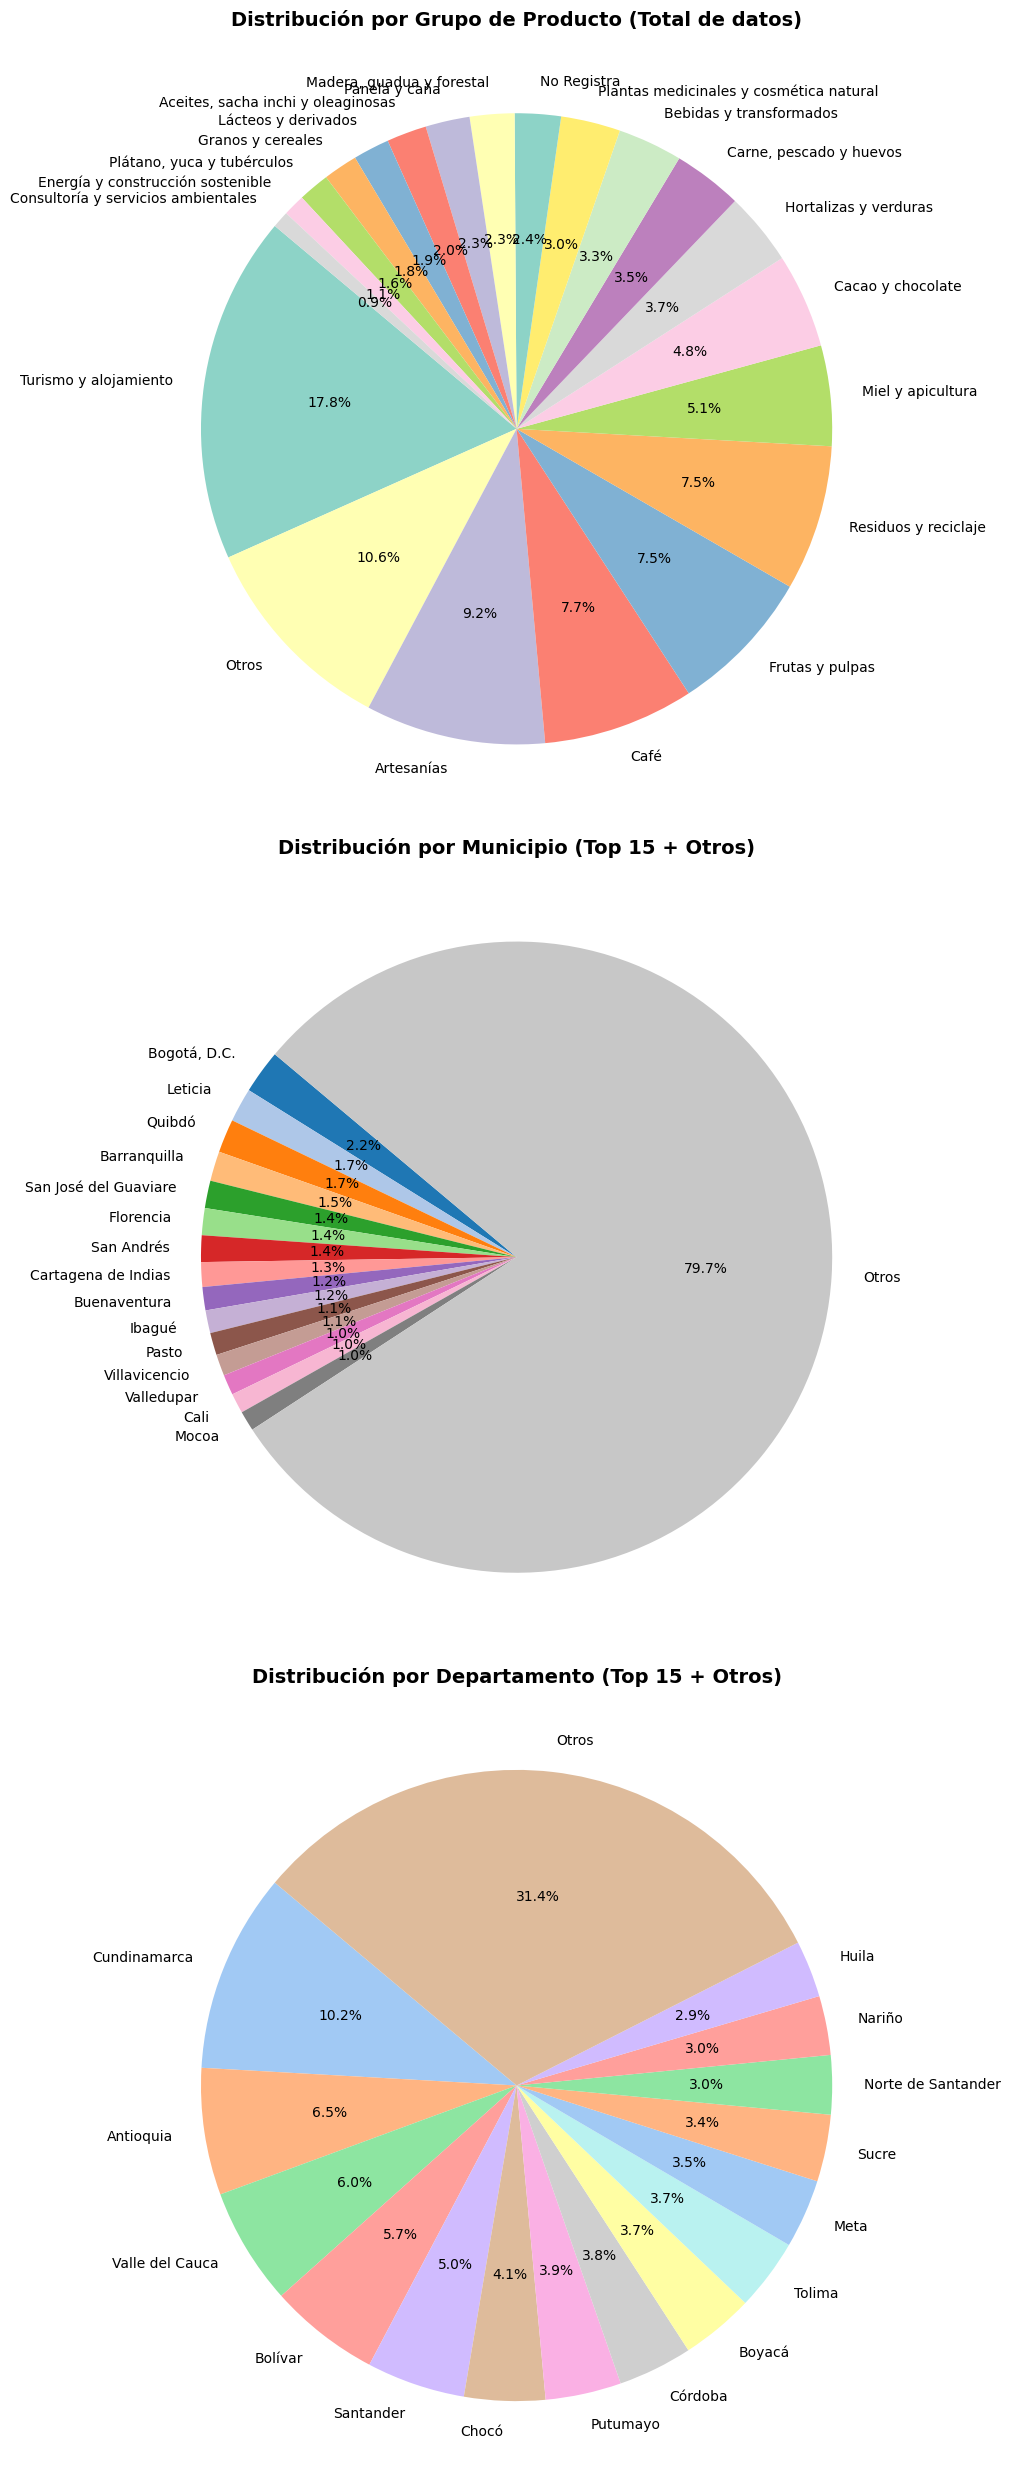

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 25))

# Diagrama de torta para grupo_producto
grupo_counts = tabla["grupo_producto"].value_counts()
axes[0].pie(grupo_counts, labels=grupo_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Set3", len(grupo_counts)))
axes[0].set_title("Distribución por Grupo de Producto (Total de datos)", fontsize=14, fontweight="bold")

# Diagrama de torta para MUNICIPIO
# Nota: Al haber más de 700 municipios, agrupamos los menores para que sea legible el gráfico de torta
mun_counts = tabla["MUNICIPIO"].value_counts()
top_mun_counts = mun_counts.head(15)
otros_mun_count = pd.Series({"Otros": mun_counts.iloc[15:].sum()})
mun_data = pd.concat([top_mun_counts, otros_mun_count])
axes[1].pie(mun_data, labels=mun_data.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("tab20", len(mun_data)))
axes[1].set_title("Distribución por Municipio (Top 15 + Otros)", fontsize=14, fontweight="bold")

# Diagrama de torta para DEPARTAMENTO
# Agrupamos departamentos menores de forma similar
depto_counts = tabla["DEPARTAMENTO"].value_counts()
top_depto_counts = depto_counts.head(15)
otros_depto_count = pd.Series({"Otros": depto_counts.iloc[15:].sum()})
depto_data = pd.concat([top_depto_counts, otros_depto_count])
axes[2].pie(depto_data, labels=depto_data.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel", len(depto_data)))
axes[2].set_title("Distribución por Departamento (Top 15 + Otros)", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

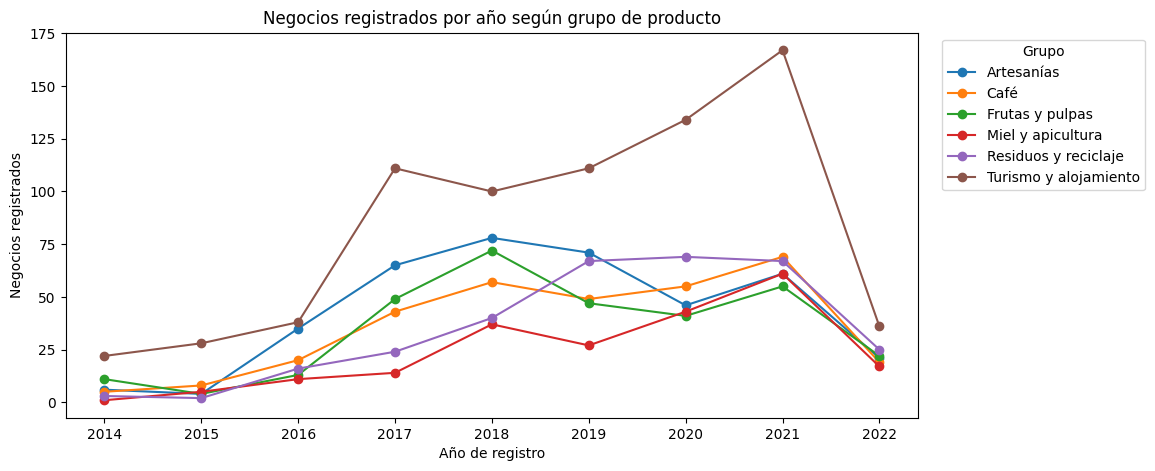

grupo_producto,Artesanías,Café,Frutas y pulpas,Miel y apicultura,Residuos y reciclaje,Turismo y alojamiento
ANO REGISTRO,,,,,,
2014,8.3,6.9,15.3,1.4,4.2,30.6
2015,5.1,10.1,5.1,6.3,2.5,35.4
2016,15.0,8.6,5.6,4.7,6.9,16.3
2017,13.8,9.1,10.4,3.0,5.1,23.6
2018,11.6,8.4,10.7,5.5,5.9,14.8
2019,9.3,6.4,6.2,3.5,8.8,14.6
2020,6.1,7.3,5.4,5.7,9.2,17.8
2021,6.7,7.6,6.1,6.7,7.4,18.4
2022,8.5,7.7,8.9,6.9,10.1,14.6


In [ ]:
# Tendencia temporal: evolución de los grupos principales por año de registro
top_grupos = tabla["grupo_producto"].value_counts().drop("Otros").head(6).index
evol = (tabla[tabla["grupo_producto"].isin(top_grupos)]
        .groupby(["ANO REGISTRO", "grupo_producto"]).size().unstack(fill_value=0))

evol.plot(marker="o", figsize=(11, 5))
plt.title("Negocios registrados por año según grupo de producto")
plt.ylabel("Negocios registrados")
plt.xlabel("Año de registro")
plt.legend(title="Grupo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

# Participación (%) dentro de cada año, para quitar el efecto del volumen de registros
(evol.div(tabla.groupby("ANO REGISTRO").size(), axis=0) * 100).round(1)

In [ ]:
tabla["MUNICIPIO"].value_counts().describe()  # muchos municipios con 1 o 2 negocios

,count
count,717.000000
mean,5.856346
std,9.670132
min,1.000000
25%,1.000000
50%,3.000000
75%,6.000000
max,94.000000


### Selección y construcción de variables
los datos son texto y categorías, así que hay que convertirlos a números:

- **Producto principal** → TF-IDF de las palabras del producto normalizado (≥5 apariciones).
- **Subsector** y **Categoría comercial** → one-hot (categorías con <20 negocios se agrupan en *infrecuente*).
- **Municipio y departamento NO entran al modelo.** Así los clusters se forman solo por el *tipo de negocio/producto* y después se analiza *de dónde vienen*; si entraran, el modelo agruparía por geografía y se perdería la pregunta.

No se aplica `StandardScaler`: el TF-IDF ya está normalizado y los one-hot son binarios; estandarizar inflaría el peso de columnas muy raras. Los one-hot se multiplican por 0.5 para que no dominen sobre el texto.

In [ ]:
stop = ["para", "con", "del", "las", "los", "una", "por", "que", "productos", "producto"]
tfidf = TfidfVectorizer(min_df=5, token_pattern=r"[a-z]{3,}", stop_words=stop)
X_texto = tfidf.fit_transform(tabla["producto_norm"])

ohe = OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist")
X_cat = ohe.fit_transform(tabla[["SUBSECTOR", "CATEGORIA COMERCIAL"]])

nombres = list(tfidf.get_feature_names_out()) + list(ohe.get_feature_names_out())
x = sp.hstack([X_texto, X_cat * 0.5]).toarray()

df = pd.DataFrame(x, columns=nombres)
print(df.shape)
df.iloc[:, :8].head()

(4199, 396)


,abeja,abejas,abono,abonos,accesorios,aceite,aceites,achiote
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### t-SNE

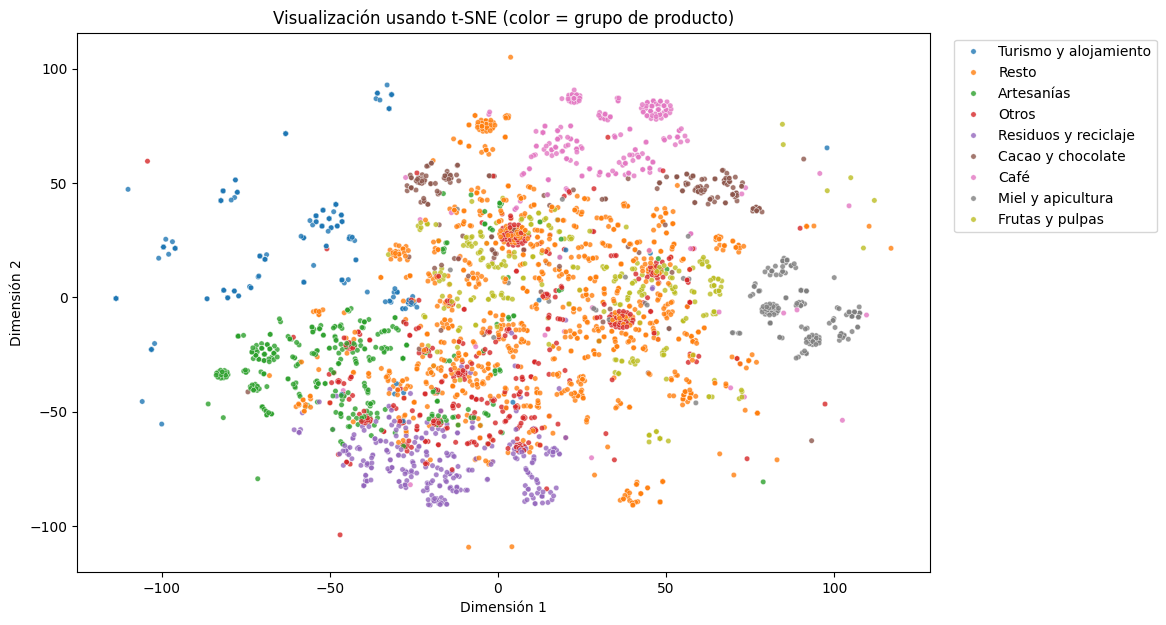

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca")
X_tsne = tsne.fit_transform(x)

top8 = tabla["grupo_producto"].value_counts().head(8).index
color = tabla["grupo_producto"].where(tabla["grupo_producto"].isin(top8), "Resto")

plt.figure(figsize=(11, 7))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=color, palette="tab10", s=15, alpha=0.8)
plt.title("Visualización usando t-SNE (color = grupo de producto)")
plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### PCA

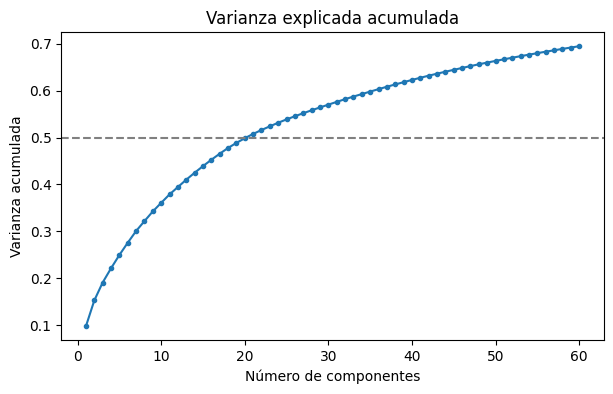

2 componentes -> 15.3%
10 componentes -> 36.1%
20 componentes -> 49.9%
30 componentes -> 57.0%
60 componentes -> 69.5%


In [ ]:
pca_full = PCA().fit(x)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 61), var_acum[:60], marker="o", markersize=3)
plt.axhline(0.5, color="gray", linestyle="--")
plt.title("Varianza explicada acumulada")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.show()

for n in [2, 10, 20, 30, 60]:
    print(f"{n} componentes -> {var_acum[n-1]:.1%}")

In [ ]:
pca = PCA(60, random_state=42)
x_pca20 = pca.fit_transform(x)
x_pca = x_pca20[:, :2]          # para graficar

print(x.shape, x_pca20.shape)
print("Varianza explicada (20 comp):", pca.explained_variance_ratio_.sum().round(3))
print("Varianza explicada PC1, PC2:", pca.explained_variance_ratio_[:2].round(3))

(4199, 396) (4199, 60)
Varianza explicada (20 comp): 0.695
Varianza explicada PC1, PC2: [0.098 0.055]


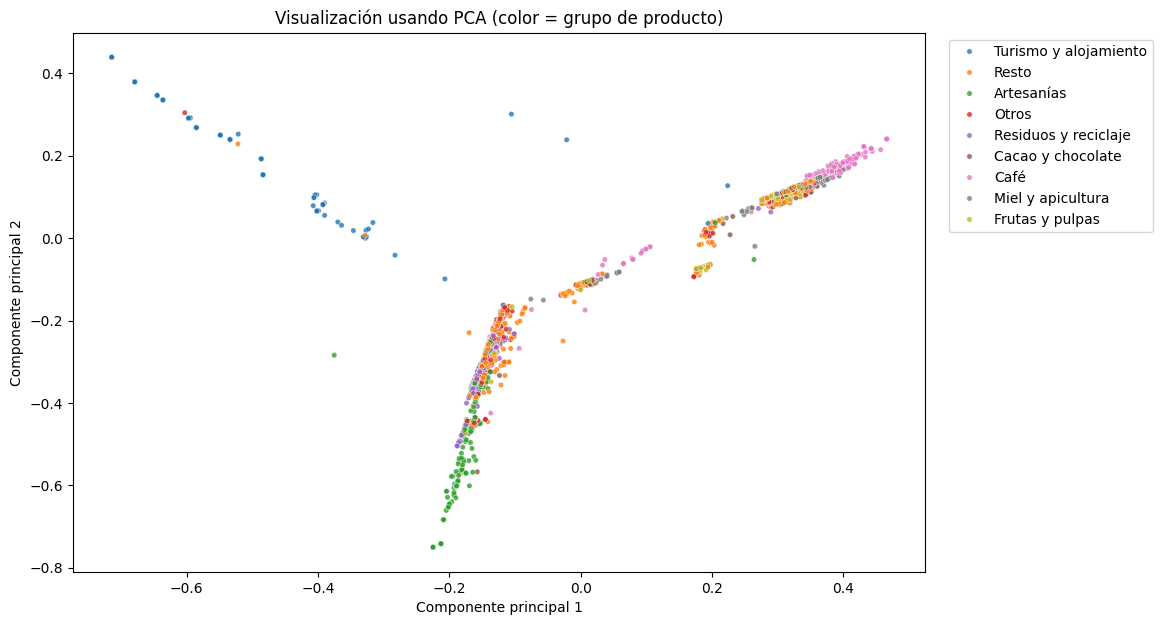

In [ ]:
color = tabla["grupo_producto"].where(tabla["grupo_producto"].isin(top8), "Resto")

plt.figure(figsize=(11, 7))
sns.scatterplot(x=x_pca[:, 0], y=x_pca[:, 1], hue=color, palette="tab10", s=15, alpha=0.8)
plt.title("Visualización usando PCA (color = grupo de producto)")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

# CLUSTERING

### Método del codo (y silueta)

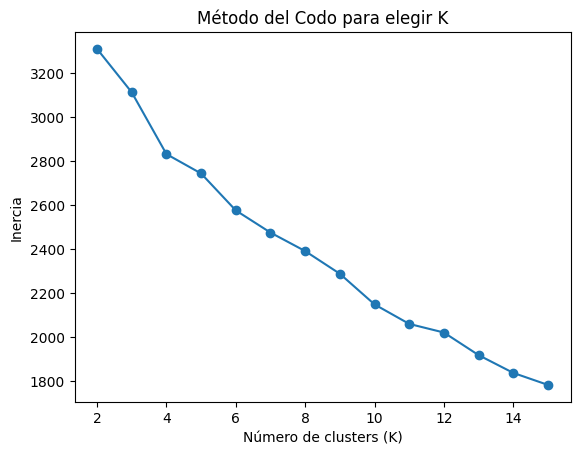

In [ ]:
inertias, sils = [], []
k_range = range(2, 16)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(x_pca20)
    inertias.append(km.inertia_)

plt.plot(k_range, inertias, marker='o')
plt.title('Método del Codo para elegir K')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.show()

### Modelado K-Means

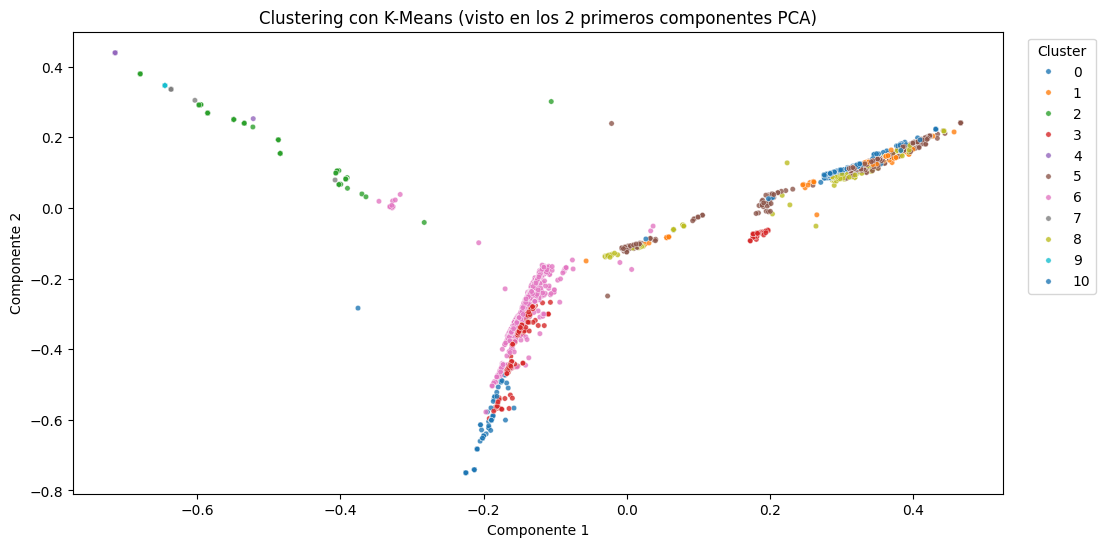

In [ ]:
kmeans = KMeans(n_clusters=11, random_state=42, n_init=10)
etiquetas = kmeans.fit(x_pca20)


plt.figure(figsize=(12, 6))
sns.scatterplot(x=x_pca[:, 0], y=x_pca[:, 1], hue=etiquetas.labels_, palette="tab10", s=15, alpha=0.8)
plt.title("Clustering con K-Means (visto en los 2 primeros componentes PCA)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### Modelado DBSCAN

Resultados de DBSCAN (eps=0.18, min_samples=15):
  - Número de clusters detectados: 54
  - Cantidad de puntos de ruido (outliers): 1774 (42.2% del total)


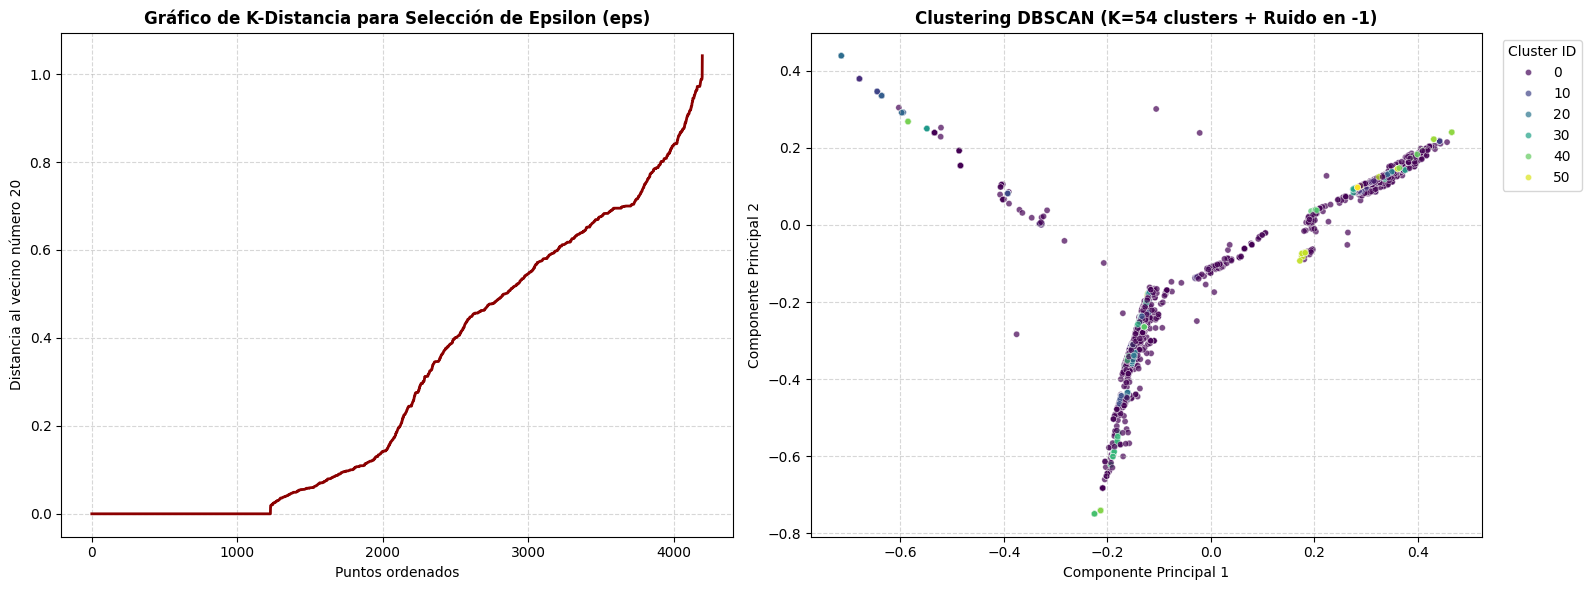

In [ ]:
# 1. Determinar el valor óptimo de eps usando la distancia a los k-vecinos más cercanos
vecinos = NearestNeighbors(n_neighbors=20)
vecinos_fit = vecinos.fit(x_pca20)
distancias, indices = vecinos_fit.kneighbors(x_pca20)

# Ordenar distancias para graficar
distancias_ordenadas = np.sort(distancias[:, -1])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfica de K-distancia
axes[0].plot(distancias_ordenadas, color="darkred", lw=2)
axes[0].set_title("Gráfico de K-Distancia para Selección de Epsilon (eps)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Puntos ordenados")
axes[0].set_ylabel("Distancia al vecino número 20")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Configurar y entrenar DBSCAN
# Usamos un valor estimado de eps basado en la curvatura de la distancia
eps_estimado = 0.18
min_samples_estimado = 15

dbscan = DBSCAN(eps=eps_estimado, min_samples=min_samples_estimado)
etiquetas_db = dbscan.fit_predict(x_pca20)

# Contar clusters y ruido
n_clusters = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)
n_ruido = list(etiquetas_db).count(-1)

print(f"Resultados de DBSCAN (eps={eps_estimado}, min_samples={min_samples_estimado}):")
print(f"  - Número de clusters detectados: {n_clusters}")
print(f"  - Cantidad de puntos de ruido (outliers): {n_ruido} ({round(100 * n_ruido / len(x_pca20), 1)}% del total)")

# 3. Visualizar los clusters generados con DBSCAN en el plano PCA
sns.scatterplot(
    x=x_pca[:, 0],
    y=x_pca[:, 1],
    hue=etiquetas_db,
    palette="tab10" if n_clusters <= 10 else "viridis",
    s=20,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title(f"Clustering DBSCAN (K={n_clusters} clusters + Ruido en -1)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Componente Principal 1")
axes[1].set_ylabel("Componente Principal 2")
axes[1].legend(title="Cluster ID", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ANALISIS DE CLUSTERS

In [ ]:
tabla["Cluster"] = kmeans.labels_
data_clusters = pd.concat([df, tabla["Cluster"]], axis=1)
data_clusters.head()

,abeja,abejas,abono,abonos,accesorios,aceite,aceites,achiote,actividades,agencia,...,CATEGORIA COMERCIAL_Consultorías y asesorías ambientales,CATEGORIA COMERCIAL_Energías renovables,CATEGORIA COMERCIAL_Hogar y estilo de vida,CATEGORIA COMERCIAL_Negocios para la acción climática,CATEGORIA COMERCIAL_No registra,CATEGORIA COMERCIAL_Productos de material reciclado,CATEGORIA COMERCIAL_Turismo sostenible,CATEGORIA COMERCIAL_Árboles y semillas,CATEGORIA COMERCIAL_infrequent_sklearn,Cluster
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,2
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,5
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,5
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,5
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.0,0.0,6


In [ ]:
# Tamaño y perfil de cada cluster: grupo dominante, pureza y subsector más común
resumen = []
for c, g in tabla.groupby("Cluster"):
    vc = g["grupo_producto"].value_counts()
    resumen.append({
        "Cluster": c,
        "negocios": len(g),
        "grupo_dominante": vc.index[0],
        "% del grupo dominante": round(100 * vc.iloc[0] / len(g), 1),
        "subsector_top": g["SUBSECTOR"].value_counts().index[0],
        "cat_comercial_top": g["CATEGORIA COMERCIAL"].value_counts().index[0],
    })
resumen = pd.DataFrame(resumen).set_index("Cluster")
resumen

,negocios,grupo_dominante,% del grupo dominante,subsector_top,cat_comercial_top
Cluster,,,,,
0,142,Artesanías,98.6,1.3.4. No Maderables,Arte y moda sostenible
1,191,Miel y apicultura,98.4,1.1.2. Agroecología,Alimentos y bebidas
2,375,Turismo y alojamiento,99.7,1.3.2. Turismo de naturaleza (ecoturismo),Turismo sostenible
3,266,Artesanías,43.6,1.3.4. No Maderables,Arte y moda sostenible
4,143,Turismo y alojamiento,100.0,1.3.2. Turismo de naturaleza (ecoturismo),Turismo sostenible
5,832,Café,17.7,1.2.1. Agroindustrial alimentario,Alimentos y bebidas
6,980,Residuos y reciclaje,31.6,2.1.2. Aprovechamiento de residuos inorgánicos,Hogar y estilo de vida
7,96,Turismo y alojamiento,99.0,1.3.2. Turismo de naturaleza (ecoturismo),Turismo sostenible
8,585,"Carne, pescado y huevos",13.3,1.1.2. Agroecología,Alimentos y bebidas


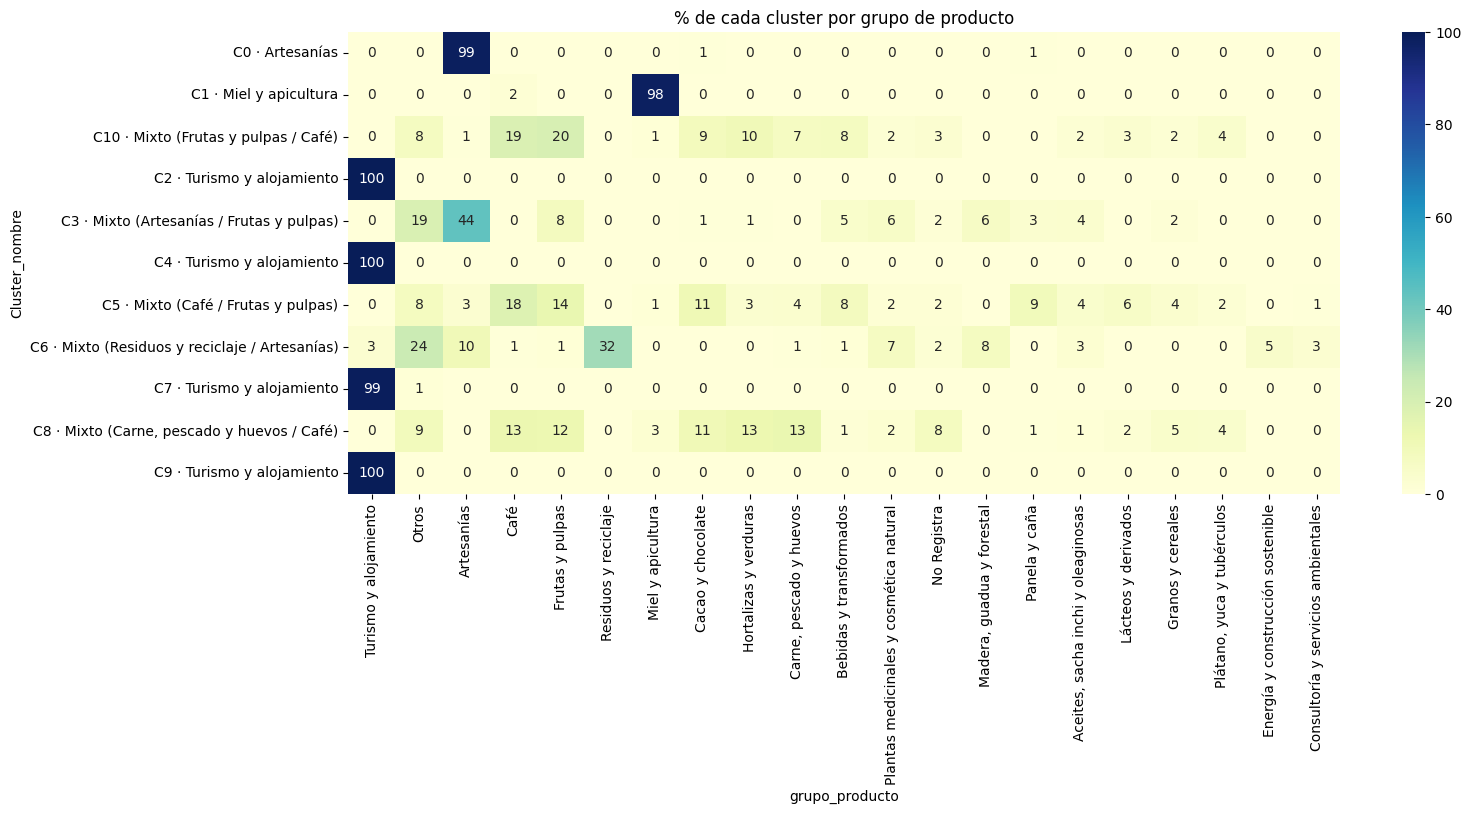

In [ ]:
# Etiqueta legible por cluster (grupo dominante)
# Si el grupo dominante no llega al 50% el cluster es "mixto": se nombra con sus 2 grupos principales
etiqueta = {}
for c, r in resumen.iterrows():
    if r["% del grupo dominante"] >= 50:
        etiqueta[c] = f"C{c} · {r['grupo_dominante']}"
    else:
        top2 = tabla.loc[tabla["Cluster"] == c, "grupo_producto"].value_counts().drop("Otros", errors="ignore").head(2).index
        etiqueta[c] = f"C{c} · Mixto ({top2[0]} / {top2[1]})"
etiqueta
tabla["Cluster_nombre"] = tabla["Cluster"].map(etiqueta)

# Cluster vs grupo de producto (% por fila): qué tan "puro" es cada cluster
cruce = pd.crosstab(tabla["Cluster_nombre"], tabla["grupo_producto"], normalize="index") * 100
cols = tabla["grupo_producto"].value_counts().index
plt.figure(figsize=(16, 6))
sns.heatmap(cruce[cols], annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("% de cada cluster por grupo de producto")
plt.show()

In [ ]:
# Productos más repetidos y municipios/departamentos de origen por cluster
for c in sorted(tabla["Cluster"].unique()):
    g = tabla[tabla["Cluster"] == c]
    print("=" * 90)
    print(f"{etiqueta[c]}  |  {len(g)} negocios")
    print("  Productos :", ", ".join(f"{k} ({v})" for k, v in g["producto_norm"].value_counts().head(5).items()))
    print("  Municipios:", ", ".join(f"{k} ({v})" for k, v in g["MUNICIPIO"].value_counts().head(5).items()))
    print("  Deptos    :", ", ".join(f"{k} ({v})" for k, v in g["DEPARTAMENTO"].value_counts().head(3).items()))

C0 · Artesanías  |  142 negocios
  Productos : artesanias (94), fabricacion de artesanias (3), artesanias- cesteria (2), artesanias, bisuteria, bolsos, juguetes y souvenir. (1), artesanias - puf (1)
  Municipios: Florencia (10), Buenaventura (7), Leticia (7), Quibdó (5), Puerto Leguízamo (4)
  Deptos    : Quindío (14), Caquetá (13), Chocó (10)
C1 · Miel y apicultura  |  191 negocios
  Productos : miel de abejas (63), miel (56), miel de abeja (11), miel de abeja y derivados (11), produccion de miel (6)
  Municipios: Ovejas (5), Zipaquirá (5), Pereira (5), Tierralta (5), Colosó (3)
  Deptos    : Cundinamarca (34), Sucre (20), Boyacá (16)
C2 · Turismo y alojamiento  |  375 negocios
  Productos : alojamiento (123), agroturismo (71), guianza (66), senderismo (64), turismo de aventura (25)
  Municipios: San José del Guaviare (17), San Andrés (12), Ibagué (12), Nuquí (11), Florencia (9)
  Deptos    : Cundinamarca (33), Tolima (28), Chocó (24)
C3 · Mixto (Artesanías / Frutas y pulpas)  |  266 

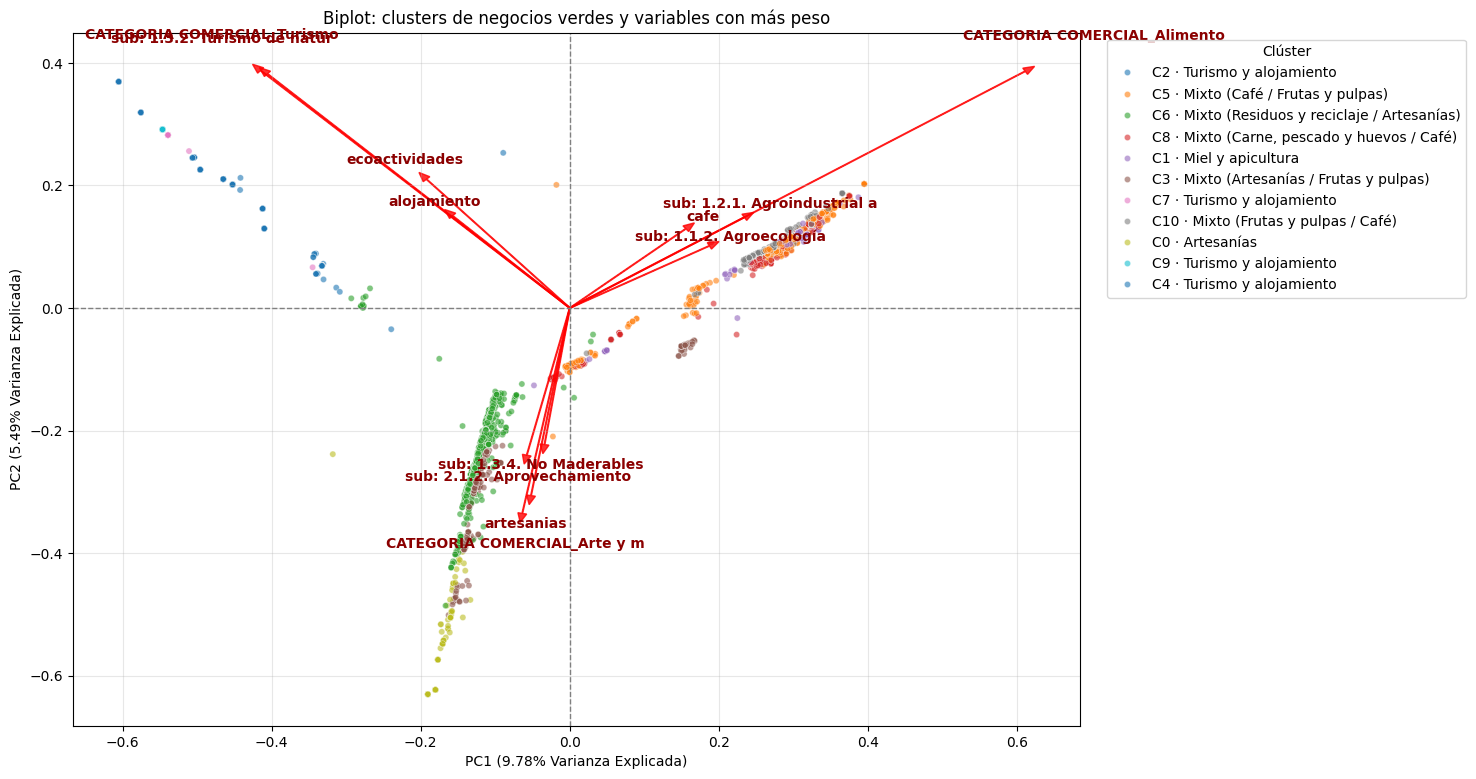

In [ ]:
# Función para generar el Biplot (PC1 vs PC2 con las variables que más pesan)
def biplot(score, coeff, labels, clusters, n_vars=12):
    plt.figure(figsize=(13, 9))
    xs, ys = score[:, 0], score[:, 1]
    scalex = 1.0 / (xs.max() - xs.min())
    scaley = 1.0 / (ys.max() - ys.min())

    sns.scatterplot(x=xs * scalex, y=ys * scaley, hue=pd.Series(clusters).map(etiqueta),
                    palette="tab10", s=20, alpha=0.6)
    plt.legend(title="Clúster", bbox_to_anchor=(1.02, 1), loc="upper left")

    # solo las variables con mayor carga (hay cientos)
    idx = np.argsort(-np.hypot(coeff[:, 0], coeff[:, 1]))[:n_vars]
    for i in idx:
        plt.arrow(0, 0, coeff[i, 0], coeff[i, 1], color="red", alpha=0.8, head_width=0.012, head_length=0.015)
        plt.text(coeff[i, 0] * 1.15, coeff[i, 1] * 1.15, labels[i].replace("CATEGORÍA COMERCIAL_", "cat: ").replace("SUBSECTOR_", "sub: ")[:28],
                 color="darkred", ha="center", va="center", fontsize=10, fontweight="bold")

    var_pc1 = pca.explained_variance_ratio_[0] * 100
    var_pc2 = pca.explained_variance_ratio_[1] * 100
    plt.xlabel(f"PC1 ({var_pc1:.2f}% Varianza Explicada)")
    plt.ylabel(f"PC2 ({var_pc2:.2f}% Varianza Explicada)")
    plt.title("Biplot: clusters de negocios verdes y variables con más peso")
    plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    plt.axvline(0, color="gray", linestyle="--", linewidth=1)
    plt.grid(alpha=0.3)
    plt.show()

biplot(x_pca, np.transpose(pca.components_[:2]), np.array(nombres), kmeans.labels_)

# TENDENCIAS: PRODUCTOS Y MUNICIPIOS DE ORIGEN

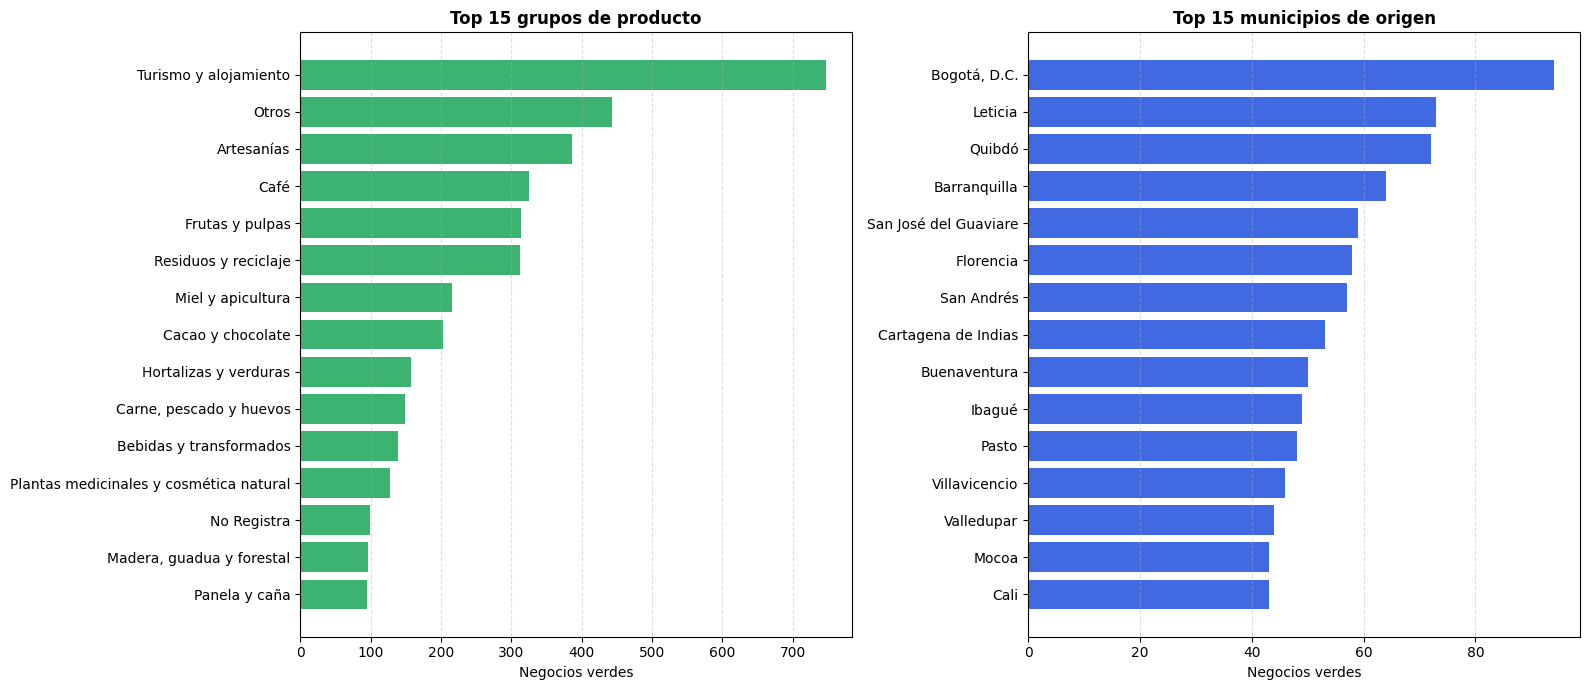

In [ ]:
# ============================================
# COMPARACIÓN LADO A LADO: PRODUCTOS (texto libre) vs MUNICIPIOS
# ============================================
top_prod = tabla["grupo_producto"].value_counts().head(15).sort_values()
top_mun = tabla["MUNICIPIO"].value_counts().head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(top_prod.index, top_prod.values, color="mediumseagreen")
axes[0].set_title("Top 15 grupos de producto", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Negocios verdes")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

axes[1].barh(top_mun.index, top_mun.values, color="royalblue")
axes[1].set_title("Top 15 municipios de origen", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Negocios verdes")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# Productos específicos más repetidos
prod_top = tabla["producto_norm"].value_counts().head(20)
prod_top

,count
producto_norm,
ecoactividades,143
alojamiento,123
operador y agencia de viajes,101
cafe,94
artesanias,94
centro ecoturistico,94
no registra,83
agroturismo,72
guianza,66


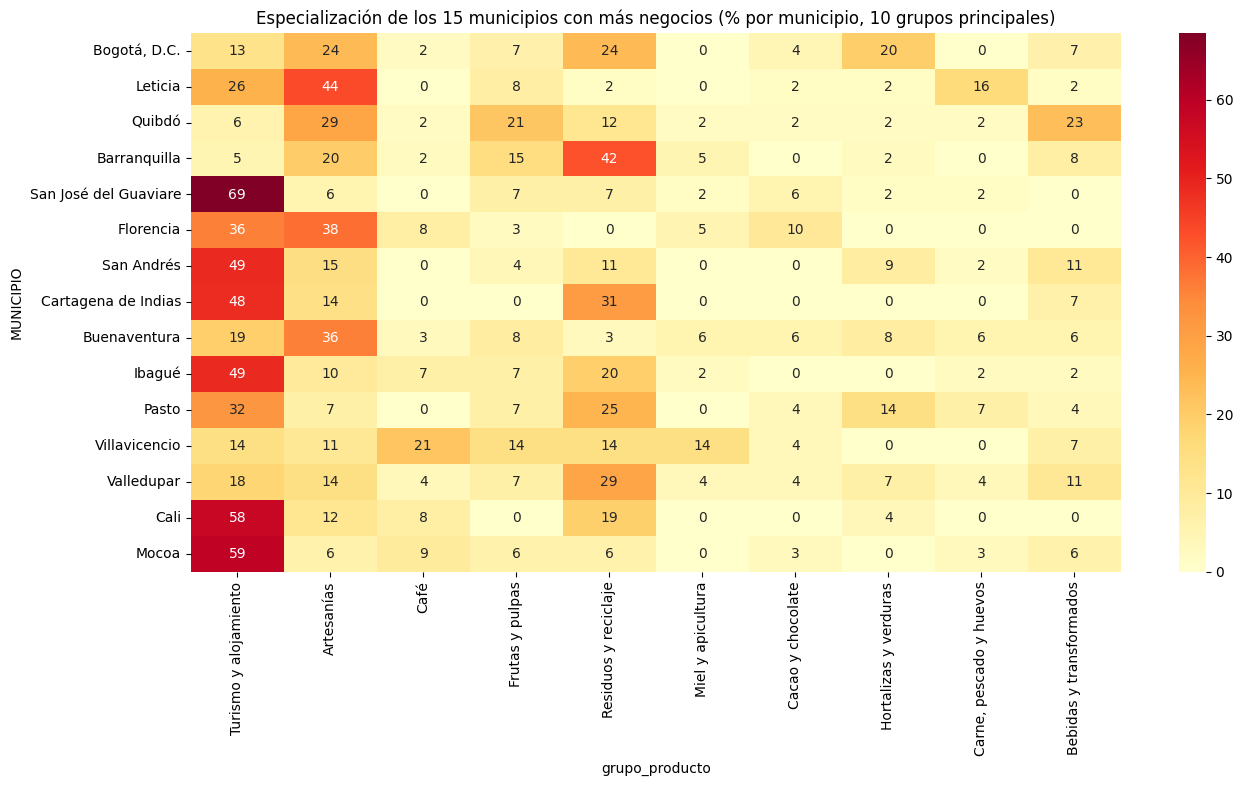

In [ ]:
# Municipio x grupo de producto: ¿qué produce cada municipio grande? (% por fila)
top_mun_names = tabla["MUNICIPIO"].value_counts().head(15).index
top_grp_names = tabla["grupo_producto"].value_counts().drop("Otros").head(10).index

cruz = pd.crosstab(tabla["MUNICIPIO"], tabla["grupo_producto"]).loc[top_mun_names, top_grp_names]
plt.figure(figsize=(15, 7))
sns.heatmap(cruz.div(cruz.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Especialización de los 15 municipios con más negocios (% por municipio, 10 grupos principales)")
plt.show()

In [ ]:
# Especialización: municipios cuyo peso en un grupo supera con claridad su peso nacional
# (lift = % del grupo en el municipio / % del grupo en el país). Solo municipios con >= 15 negocios.
nacional = tabla["grupo_producto"].value_counts(normalize=True)
conteo_mun = tabla["MUNICIPIO"].value_counts()
grandes = conteo_mun[conteo_mun >= 15].index

filas = []
for m in grandes:
    g = tabla[tabla["MUNICIPIO"] == m]
    comp = g["grupo_producto"].value_counts(normalize=True)
    comp = comp.drop("Otros", errors="ignore")
    grupo = comp.index[0]
    filas.append({"MUNICIPIO": m, "departamento": g["DEPARTAMENTO"].mode()[0], "negocios": len(g),
                  "grupo_estrella": grupo, "% en municipio": round(100 * comp.iloc[0], 1),
                  "lift vs país": round(comp.iloc[0] / nacional[grupo], 2)})
especializacion = pd.DataFrame(filas).sort_values("lift vs país", ascending=False)
display(especializacion)

,MUNICIPIO,departamento,negocios,grupo_estrella,% en municipio,lift vs país
20,Magangué,Bolívar,37,"Carne, pescado y huevos",40.5,11.42
52,Granada,Meta,15,No Registra,26.7,11.31
40,Cajicá,Cundinamarca,19,No Registra,26.3,11.16
47,Tenjo,Cundinamarca,16,Hortalizas y verduras,37.5,10.03
43,San Marcos,Sucre,18,Panela y caña,22.2,9.82
26,Bucaramanga,Santander,28,No Registra,21.4,9.09
53,Pueblo Bello,Cesar,15,Café,46.7,6.03
32,Tierralta,Córdoba,23,Miel y apicultura,30.4,5.92
35,Santa Rosa del Sur,Bolívar,21,Cacao y chocolate,28.6,5.91
44,Sibundoy,Putumayo,17,Artesanías,52.9,5.74


In [ ]:
# Municipio dominante por cada grupo de producto (dónde se concentra cada producto)
filas = []
for gp in top_grp_names:
    g = tabla[tabla["grupo_producto"] == gp]
    vc = g["MUNICIPIO"].value_counts()
    deps = g["DEPARTAMENTO"].value_counts()
    filas.append({"grupo_producto": gp, "negocios": len(g),
                  "top municipios": ", ".join(f"{k} ({v})" for k, v in vc.head(3).items()),
                  "top departamentos": ", ".join(f"{k} ({v})" for k, v in deps.head(3).items())})
pd.DataFrame(filas)

,grupo_producto,negocios,top municipios,top departamentos
0,Turismo y alojamiento,747,"San José del Guaviare (37), San Andrés (23), P...","Cundinamarca (53), Tolima (49), Valle del Cauc..."
1,Artesanías,387,"Leticia (27), Quibdó (15), Florencia (15)","Cundinamarca (36), Amazonas (28), Quindío (26)"
2,Café,325,"Planadas (9), Santa Marta (7), Pueblo Bello (7)","Cundinamarca (43), Antioquia (33), Tolima (25)"
3,Frutas y pulpas,314,"Quibdó (11), San José de Uré (9), Barranquilla...","Chocó (29), Antioquia (26), Cundinamarca (25)"
4,Residuos y reciclaje,313,"Barranquilla (17), Bogotá, D.C. (11), Cartagen...","Bolívar (34), Antioquia (25), Cundinamarca (21)"
5,Miel y apicultura,216,"Ovejas (7), Tierralta (7), Zipaquirá (6)","Cundinamarca (37), Sucre (22), Boyacá (16)"
6,Cacao y chocolate,203,"San Vicente de Chucurí (7), Santa Rosa del Sur...","Antioquia (22), Meta (20), Santander (20)"
7,Hortalizas y verduras,157,"Bogotá, D.C. (9), Tenjo (6), Tabio (6)","Cundinamarca (52), Boyacá (12), Valle del Cauc..."
8,"Carne, pescado y huevos",149,"Magangué (15), Leticia (10), Simití (8)","Bolívar (38), Córdoba (12), Amazonas (12)"
9,Bebidas y transformados,139,"Quibdó (12), San Andrés (5), Riohacha (5)","Chocó (16), Bolívar (11), Cesar (8)"


# Conclusiones

In [ ]:
print("Negocios analizados:", len(tabla))
print("\nTop 5 grupos de producto:")
for i, (k, v) in enumerate(tabla["grupo_producto"].value_counts().drop("Otros").head(5).items(), 1):
    print(f"{i}. {k}: {v} ({v/len(tabla):.1%})")
print("\nTop 5 municipios:")
for i, (k, v) in enumerate(tabla["MUNICIPIO"].value_counts().head(5).items(), 1):
    print(f"{i}. {k}: {v}")
print("\nTop 5 departamentos:")
for i, (k, v) in enumerate(tabla["DEPARTAMENTO"].value_counts().head(5).items(), 1):
    print(f"{i}. {k}: {v}")

Negocios analizados: 4199

Top 5 grupos de producto:
1. Turismo y alojamiento: 747 (17.8%)
2. Artesanías: 387 (9.2%)
3. Café: 325 (7.7%)
4. Frutas y pulpas: 314 (7.5%)
5. Residuos y reciclaje: 313 (7.5%)

Top 5 municipios:
1. Bogotá, D.C.: 94
2. Leticia: 73
3. Quibdó: 72
4. Barranquilla: 64
5. San José del Guaviare: 59

Top 5 departamentos:
1. Cundinamarca: 429
2. Antioquia: 273
3. Valle del Cauca: 252
4. Bolívar: 238
5. Santander: 212


### 1. Tendencias de productos principales
- **Turismo y alojamiento es el grupo número 1** con 747 negocios (18,2%). Dentro de él pesan: ecoactividades (143), alojamiento (123), operadores y agencias de viajes (101), centros ecoturísticos (94), agroturismo (72), guianza (66) y senderismo (64).
- Le siguen **artesanías (9,4%), café (7,9%), frutas y pulpas (7,7%) y residuos y reciclaje (7,6%)**; después miel y apicultura (5,3%) y cacao y chocolate (5,0%). El 10,8% quedó en *Otros* (productos muy particulares).

### 2. Municipios de origen
- La oferta está **dispersa**: 728 municipios distintos; los 10 primeros suman solo el 15% de los negocios y los 20 primeros el 25%. Casi la mitad de los municipios (339) tiene 1 o 2 negocios.
- Municipios con más negocios: **Bogotá D.C. (91), Leticia (73), Quibdó (72), Barranquilla (64), San José del Guaviare (58)**. Por departamento: **Cundinamarca (395), Antioquia (271), Valle del Cauca (250), Bolívar (234), Santander (191)**; los 5 primeros concentran el 33%.
- **Especialización (lift vs. país, solo municipios con ≥15 negocios):** Magangué (carne/pescado/huevos, 40% de sus negocios), Tenjo (hortalizas), San Marcos (panela y caña), Pueblo Bello (café, 47%), Tierralta (miel), Santa Rosa del Sur (cacao), Sibundoy y Armenia (artesanías), Nuquí, Providencia y San José del Guaviare (turismo: 81%, 65% y 64% de sus negocios).
- **Turismo de territorios remotos:** Guaviare (58% de sus negocios son de turismo) y San Andrés/Providencia (50%) lideran la proporción, seguidos por Tolima, Caquetá, Casanare y Putumayo. Los grandes centros urbanos (Bogotá, Barranquilla, Cartagena) destacan en **residuos y reciclaje**.